# TicTacLearn

### Learn by Playing: A CNN-Based Tic-Tac-Toe Game for Teaching Overfitting and Underfitting

**University of Information Technology and Sciences (UITS)** · Department of Computer Science and Engineering

| Team member | Student ID | Batch / Section |
|---|---|---|
| Md. Shahriar Hossain Srabon | 0432310005101056 | 53 / B1 |
| Lubna Jahan Lipa | 0432310005101088 | 53 / B2 |
| Tamanna Khokon | 0432310005101082 | 53 / B2 |

This notebook is **Part A** of the project. It builds the complete teaching experiment:
a clean Tic-Tac-Toe dataset labeled by minimax, three CNNs trained to underfit, overfit
and generalize, the measurements and plots that make the difference visible, and the
exported artifacts that the companion website (Part B) will use.

**How to run:** choose **Runtime > Run all** in Google Colab. A full run is designed to
take under 10 minutes on the free CPU runtime. Every random seed is fixed, so a second
run produces the same numbers.

**What this notebook produces**

1. Three trained models: `underfit`, `overfit` and `stable`.
2. Training curves, an accuracy comparison, a win/draw/loss chart and explanation heatmaps.
3. A folder of portable artifacts under `/content/artifacts/`, zipped as `artifacts.zip`:
   Keras models, TensorFlow.js models, metrics and histories as JSON, and plots as PNG.
4. A teacher summary that maps each course concept to the cell that demonstrates it and
   the measured evidence.

The notebook is deliberately written for a reader who knows some machine learning but has
not seen this code before: every code cell is preceded by a short explanation of what it
does and what output to expect.

## 1. Setup

### 1.1 Install only what is missing

Colab already provides TensorFlow and matplotlib. The only package that is usually missing
is the TensorFlow.js converter used at export time. We install it only when the import
check fails, and the version is pinned so two runs use the same code.

**Expected output:** one `Library check finished.` line, preceded by a short pip install
line if a package was missing.

In [1]:
# Install only packages that are missing. Versions are pinned for reproducibility.
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "tensorflow": "tensorflow-cpu==2.21.0",
    "matplotlib": "matplotlib==3.10.9",
    "tensorflowjs": "tensorflowjs==4.22.0",
}
for module, requirement in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(module) is None:
        print(f"Installing {requirement} ...")
        result = subprocess.call(
            [sys.executable, "-m", "pip", "install", "-q", requirement]
        )
        if result != 0:
            print(
                f"WARNING: could not install {requirement}. "
                "The notebook will continue and use the documented fallback."
            )
print("Library check finished.")

Library check finished.


### 1.2 Imports, seeds, artifact folders and shared configuration

Machine-learning results can change if random numbers change, so this cell sets one seed for
Python, NumPy and TensorFlow, and asks TensorFlow to use deterministic operations. It also
creates the artifact folders and fills one `CONFIG` dictionary with every hyperparameter, so
no number is hidden inside a later cell.

Artifacts go to `/content/artifacts` in Colab. When the notebook is executed by the local
verification runner, `TTT_ARTIFACT_DIR` points at the repository's `artifacts/` folder
instead. The notebook itself never contains a machine-specific path.

**Expected output:** versions of Python, TensorFlow, Keras and matplotlib, the artifact
folder path, and no error.

In [2]:
# Environment flags must be set before TensorFlow is imported.
import os
import random
import sys

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

import json
import time
from collections import Counter, defaultdict, deque
from pathlib import Path
from typing import Optional, Sequence

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import keras

# One seed for every source of randomness used in this notebook.
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:  # older TensorFlow fallback
    pass

# Artifact locations (Colab default; the local runner overrides the base folder).
ARTIFACT_DIR = Path(os.environ.get("TTT_ARTIFACT_DIR", "/content/artifacts"))
MODEL_DIR = ARTIFACT_DIR / "models"
DATA_DIR = ARTIFACT_DIR / "data"
PLOT_DIR = ARTIFACT_DIR / "plots"
for directory in (MODEL_DIR, DATA_DIR, PLOT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Consistent, legible plots: large fonts and room for labels.
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 170,
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

CONFIG = {
    # Data
    "seed": SEED,
    "split": {"train": 0.70, "val": 0.15, "test": 0.15},  # by symmetry group
    "overfit_subset_size": 60,  # boards the memorizing model may see (tuned for >= 25% val gap)
    # Training. These are starting points; section 10 tunes them until the targets pass.
    "underfit": {"epochs": 3, "batch_size": 64, "learning_rate": 1e-4},
    "overfit": {"epochs": 300, "batch_size": 16, "learning_rate": 1e-3},
    "stable": {
        "epochs": 60,
        "batch_size": 64,
        "learning_rate": 1e-3,
        "early_stopping_patience": 10,
    },
    # Evaluation
    "games": {"vs_random": 1000, "vs_minimax": 200},
    "parity_boards_per_model": 20,
}

print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {keras.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
try:
    import tensorflowjs

    print(f"tensorflowjs: {tensorflowjs.__version__}")
except Exception:
    print("tensorflowjs: not importable yet (needed only in the export section)")
print(f"Artifacts   : {ARTIFACT_DIR}")

Python      : 3.10.11
TensorFlow  : 2.21.0
Keras       : 3.12.4
NumPy       : 2.2.6
Matplotlib  : 3.10.9


tensorflowjs: not importable yet (needed only in the export section)
Artifacts   : D:\Projects\Neural Network Cnn tic-tac toe\artifacts


## 2. Concepts primer (plain language)

### What is a convolutional neural network?

A convolutional neural network (CNN) is a model that looks for **small local patterns**
and combines them. For a 3×3 board, a pattern is something like "two of my marks in a row
with the third cell empty" or "the opponent has a corner and the centre". The model does not
receive a rule book; it adjusts its internal pattern detectors until its answers fit the
training examples.

### What is a filter?

A **filter** (or kernel) is one tiny pattern detector, usually 3×3, that slides across the
board and produces a score for every position: "how strongly does this pattern appear here?"
A CNN learns the numbers inside its filters. With only two filters, the model can recognise
very few patterns; with dozens of filters per layer, it can recognise many.

### Underfitting, overfitting and generalization

| Model | Student analogy | Technical name | What you will see |
|---|---|---|---|
| `underfit` | Skimmed the book for five minutes | Underfitting (too little capacity/training) | Low accuracy on training **and** new boards |
| `overfit` | Memorized last year's answers | Overfitting (memorization, no regularization) | Near-perfect training accuracy, much worse on new boards |
| `stable` | Understood the concepts | Good generalization | High accuracy on both training and new boards |

**Generalization** means doing well on boards that were not used for training. It is the
only result that matters for a player, because a real game constantly produces new boards.

### Accuracy and loss

- **Loss** measures how far the predicted probabilities are from the ideal answer. Lower is
  better. The optimizer reduces training loss step by step.
- **Accuracy** here means: after ignoring cells that are already taken, did the model's
  highest-probability move belong to the set of optimal minimax moves?

A large gap between the training curve and the validation curve is the visual signature of
overfitting. Both curves being poor is the signature of underfitting. Two curves that stay
close and high are the signature of good generalization.

### Why the split must be leak-free

Tic-Tac-Toe boards have eight symmetries: four rotations and their mirror images. If we
split boards at random, a rotated copy of a training board could land in the test set; the
model would look better than it really is. We group all symmetric copies of a board
together and split **by group**, so test boards are genuinely new shapes.

### What "optimal" means here

Minimax is a perfect-play algorithm. For every non-terminal board it returns the score of
the game with perfect play and the set of moves that achieve that score. Sometimes several
moves are equally optimal, so the training target is a **uniform distribution over that
set**, not a single "correct" cell. A prediction is counted as correct when its best legal
move is in that set.

## 3. Game rules and symmetries

### 3.1 Board representation

Inside the game logic a board is a tuple of nine numbers, indexed row by row from `0`
(top-left) to `8` (bottom-right). We use **absolute** marks here: `X = +1`, `O = -1`,
empty `= 0`. Later, immediately before a board enters a model, we convert it to the
**player-to-move perspective** required by the project: the player who must move sees their
own marks as `+1` and the opponent's as `-1`.

### 3.2 Rules

The functions below are deliberately tiny and pure: no global state, no printing, and the
input board is never mutated. The following cell checks them with `assert`, so a mistake
stops the notebook immediately instead of silently corrupting the dataset.

In [3]:
# Absolute board values used by the game logic.
X, O, EMPTY = 1, -1, 0

# The eight winning lines as cell indices (0..8, row-major).
LINES: tuple[tuple[int, int, int], ...] = (
    (0, 1, 2), (3, 4, 5), (6, 7, 8),   # rows
    (0, 3, 6), (1, 4, 7), (2, 5, 8),   # columns
    (0, 4, 8), (2, 4, 6),              # diagonals
)


def other(player: int) -> int:
    """Return the opposing player."""
    return -player


def winner(board: Sequence[int]) -> Optional[int]:
    """Return X or O if that player has three in a row, otherwise None."""
    for a, b, c in LINES:
        if board[a] != EMPTY and board[a] == board[b] == board[c]:
            return board[a]
    return None


def legal_moves(board: Sequence[int]) -> list[int]:
    """Return the indices of all empty cells, in row-major order."""
    return [index for index, value in enumerate(board) if value == EMPTY]


def is_full(board: Sequence[int]) -> bool:
    """True when no cell is empty."""
    return all(value != EMPTY for value in board)


def is_terminal(board: Sequence[int]) -> bool:
    """True when the game is won or drawn."""
    return winner(board) is not None or is_full(board)


def play(board: Sequence[int], move: int, player: int) -> tuple[int, ...]:
    """Place `player` on `move` and return a new board; the input is unchanged."""
    if board[move] != EMPTY:
        raise ValueError(f"cell {move} is already occupied")
    updated = list(board)
    updated[move] = player
    return tuple(updated)


def to_mover_perspective(board: Sequence[int], player: int) -> np.ndarray:
    """Model input: own marks +1, opponent marks -1, empty 0, shape (3, 3, 1)."""
    return np.asarray(board, dtype=np.float32).reshape(3, 3, 1) * player


def format_board(board: Sequence[int]) -> str:
    """A compact three-line text view, useful for debugging and explanations."""
    symbols = {EMPTY: ".", X: "X", O: "O"}
    return "\n".join(
        " ".join(symbols[board[row * 3 + column]] for column in range(3))
        for row in range(3)
    )

**Checks.** The next cell asserts the rules with small, readable examples. If any rule is
wrong, the notebook stops here instead of building a corrupt dataset.

**Expected output:** `Game rule checks passed.` followed by a three-line example board.

In [4]:
# Checks a reader can trust before anything is built on top of these helpers.
assert winner((X, X, X, 0, 0, 0, 0, 0, 0)) == X
assert winner((O, O, O, 0, 0, 0, 0, 0, 0)) == O
assert winner((X, O, X, O, X, O, O, X, O)) is None  # full board, no line
assert legal_moves((X, 0, O, 0, 0, 0, 0, 0, 0)) == [1, 3, 4, 5, 6, 7, 8]
assert play((0,) * 9, 4, X)[4] == X
assert is_terminal((X, X, X, 0, 0, 0, 0, 0, 0))
assert not is_terminal((0,) * 9)

sample_board = (X, EMPTY, O, EMPTY, X, EMPTY, EMPTY, O, EMPTY)
assert format_board(sample_board).count("X") == 2
assert to_mover_perspective(sample_board, O).shape == (3, 3, 1)
assert to_mover_perspective(sample_board, O)[0, 0, 0] == -1  # X seen by O is -1

print("Game rule checks passed. Example board:")
print(format_board(sample_board))

Game rule checks passed. Example board:
X . O
. X .
. O .


### 3.3 The eight symmetries

Rotating or mirroring a Tic-Tac-Toe board does not change the value of a position. There
are four rotations, and each one can be mirrored, giving eight symmetric versions.

We represent each symmetry as a **permutation of cell indices**: `transformed[i] = original[perm[i]]`.
The same permutation can then be applied to a board, an optimal-move vector or a predicted
probability vector, which keeps inputs and labels aligned during augmentation. The
**canonical form** of a board is the lexicographically smallest of its eight versions; two
boards that are rotations or mirrors of each other share the same canonical form.

In [5]:
def symmetry_permutations() -> tuple[tuple[int, ...], ...]:
    """The eight index permutations: four rotations, with and without a mirror."""
    base = np.arange(9).reshape(3, 3)
    permutations = []
    for reflected in (False, True):
        grid = np.fliplr(base) if reflected else base
        for turns in range(4):
            permutations.append(
                tuple(int(value) for value in np.rot90(grid, turns).reshape(-1))
            )
    return tuple(permutations)


SYMMETRY_PERMS = symmetry_permutations()


def apply_permutation(values: Sequence[float], perm: Sequence[int]) -> tuple:
    """Move cell `i` to position `perm[i]`; works for boards, labels and probabilities."""
    return tuple(values[index] for index in perm)


def symmetries(board: Sequence[int]) -> list[tuple[int, ...]]:
    """All eight symmetric versions of a board."""
    return [apply_permutation(board, perm) for perm in SYMMETRY_PERMS]


def canonical(board: Sequence[int]) -> tuple[int, ...]:
    """Smallest symmetric version; equal for boards that are mirrors/rotations."""
    return min(symmetries(board))

**Checks.** The next cell confirms that the eight permutations are distinct, that a board
keeps the same pieces after every transform, and that symmetric copies share one canonical
form.

**Expected output:** `Symmetry checks passed.` and the canonical form of the example board.

In [6]:
assert len(SYMMETRY_PERMS) == 8
assert len(set(SYMMETRY_PERMS)) == 8
assert all(sorted(version) == sorted(sample_board) for version in symmetries(sample_board))
assert canonical(sample_board) == canonical(symmetries(sample_board)[5])
assert apply_permutation((0, 1, 2, 3, 4, 5, 6, 7, 8), SYMMETRY_PERMS[0]) == tuple(range(9))

print("Symmetry checks passed.")
print("Canonical form of the example board:", canonical(sample_board))

Symmetry checks passed.
Canonical form of the example board: (-1, 0, 0, 0, 1, -1, 1, 0, 0)


## 4. Minimax: the perfect-play teacher

Minimax explores every possible continuation and assumes both players always choose their
best move. Its result for a position is:

- a **score** from the player-to-move's point of view: `+1` win, `0` draw, `-1` loss;
- the **set of moves** that achieve that score.

A set is necessary because several moves can be equally optimal, especially in a symmetric
game like Tic-Tac-Toe. The search is memoized: each board is solved once, so labeling the
full dataset takes well under a second.

The three tests below are the ones a teacher is most likely to ask about: take an immediate
win, block an immediate loss, and confirm that perfect play from the empty board is a draw.

In [7]:
from functools import lru_cache


@lru_cache(maxsize=None)
def minimax(board: tuple[int, ...], player: int) -> tuple[int, tuple[int, ...]]:
    """Score and every optimal move for `player` to move, assuming perfect play.

    The score is relative to `player`: +1 win, 0 draw, -1 loss.
    """
    if winner(board) == player:
        return 1, ()
    if winner(board) == other(player):
        return -1, ()

    moves = legal_moves(board)
    if not moves:
        return 0, ()

    best_score = -2
    best_moves: list[int] = []
    for move in moves:
        child = play(board, move, player)
        child_score, _ = minimax(child, other(player))
        score = -child_score  # the opponent's gain is our loss
        if score > best_score:
            best_score, best_moves = score, [move]
        elif score == best_score:
            best_moves.append(move)
    return best_score, tuple(best_moves)

**Checks.** The next cell tests the three cases that matter most: take an immediate win,
block an immediate loss, and confirm that perfect play from the empty board is a draw with
all nine first moves equally optimal.

**Expected output:** three passing `assert`s and the printed scores and optimal move sets.

In [8]:
# 1. An immediate win is taken.
win_board = (X, X, EMPTY, O, O, EMPTY, EMPTY, EMPTY, EMPTY)
assert minimax(win_board, X) == (1, (2,))

# 2. An immediate loss is blocked (O threatens cell 5; X must play there).
block_board = (X, EMPTY, EMPTY, O, O, EMPTY, EMPTY, EMPTY, X)
block_score, block_moves = minimax(block_board, X)
assert block_score == 0, block_score
assert 5 in block_moves, block_moves

# 3. Perfect play from the empty board is a draw, and every first move is optimal.
empty_board = (EMPTY,) * 9
empty_score, empty_moves = minimax(empty_board, X)
assert empty_score == 0
assert empty_moves == tuple(range(9))

print("Minimax checks passed.")
print(f"Immediate win  -> score {minimax(win_board, X)[0]}, optimal moves {minimax(win_board, X)[1]}")
print(f"Must block     -> score {block_score}, optimal moves {block_moves}")
print(f"Empty board    -> score {empty_score}, {len(empty_moves)} equally optimal first moves")
print(f"Positions solved and cached so far: {minimax.cache_info().currsize:,}")

Minimax checks passed.
Immediate win  -> score 1, optimal moves (2,)
Must block     -> score 0, optimal moves (5,)
Empty board    -> score 0, 9 equally optimal first moves
Positions solved and cached so far: 5,478


## 5. Dataset: every reachable non-terminal position

We start from the empty board with **X to move** and explore every legal continuation.
Finished boards (a win or a draw) are not useful training examples, so we keep only
positions where the game is still running. The expected total is **4,520** positions; the
cell asserts it rather than trusting the comment.

For each position we store:

- the absolute board and who is to move (needed to simulate games);
- the model input in mover perspective;
- a **soft label**: `1 / number_of_optimal_moves` on each optimal cell and `0` elsewhere.

In [9]:
def reachable_non_terminal_positions() -> list[tuple[tuple[int, ...], int]]:
    """Breadth-first enumeration of all unfinished boards reachable with X first."""
    start = (EMPTY,) * 9
    seen = {start}
    queue = deque([(start, X)])
    positions: list[tuple[tuple[int, ...], int]] = []

    while queue:
        board, player = queue.popleft()
        if is_terminal(board):
            continue
        positions.append((board, player))
        for move in legal_moves(board):
            child = play(board, move, player)
            if child not in seen:
                seen.add(child)
                queue.append((child, other(player)))
    return positions


POSITIONS = reachable_non_terminal_positions()
BOARDS = [board for board, _ in POSITIONS]
MOVERS = np.array([player for _, player in POSITIONS], dtype=np.int8)

assert len(POSITIONS) == 4520, len(POSITIONS)
assert len({board for board, _ in POSITIONS}) == 4520
print(f"Reachable non-terminal positions: {len(POSITIONS):,}")
print(f"X to move: {int((MOVERS == X).sum()):,} | O to move: {int((MOVERS == O).sum()):,}")

Reachable non-terminal positions: 4,520
X to move: 2,423 | O to move: 2,097


**Labels and tensors.** The next cell asks minimax for the optimal set of every position,
turns that set into a uniform soft label, and stacks the model inputs and targets into
arrays. It also keeps the absolute boards for the game simulation.

**Expected output:** input shape `(4520, 3, 3, 1)`, target shape `(4520, 9)`, and the average
number of optimal moves per board.

In [10]:
def build_dataset():
    """Attach a minimax soft label to every enumerated position."""
    boards, movers, inputs, labels, optimal_sets = [], [], [], [], []
    for board, player in POSITIONS:
        score, moves = minimax(board, player)
        assert moves, "a non-terminal position must have at least one legal move"

        target = np.zeros(9, dtype=np.float32)
        target[list(moves)] = 1.0
        target /= target.sum()  # uniform over equally optimal moves

        boards.append(board)
        movers.append(player)
        inputs.append(to_mover_perspective(board, player))
        labels.append(target)
        optimal_sets.append(moves)

    return (
        np.stack(inputs),
        np.stack(labels),
        np.array(movers, dtype=np.int8),
        boards,
        optimal_sets,
    )


X_ALL, Y_ALL, MOVERS, BOARDS, OPTIMAL_MOVES = build_dataset()
OPTIMAL_BOOL = Y_ALL > 0  # membership mask: True where a move is optimal

assert X_ALL.shape == (4520, 3, 3, 1)
assert Y_ALL.shape == (4520, 9)
assert np.allclose(Y_ALL.sum(axis=1), 1.0)
print(f"Model inputs: {X_ALL.shape} | targets: {Y_ALL.shape}")
print(f"Average number of optimal moves per board: {OPTIMAL_BOOL.sum(axis=1).mean():.2f}")
print(f"Boards with more than one optimal move: {int((OPTIMAL_BOOL.sum(axis=1) > 1).sum()):,}")
print(f"Minimax cache: {minimax.cache_info().currsize:,} solved positions")

Model inputs: (4520, 3, 3, 1) | targets: (4520, 9)
Average number of optimal moves per board: 1.96
Boards with more than one optimal move: 2,114
Minimax cache: 5,478 solved positions


### 5.1 A visual sanity check

Choose one board from each stage of the game and draw it. A light green square with a
small dot marks a cell that minimax considers optimal. The dot means the information does
not rely on colour alone.

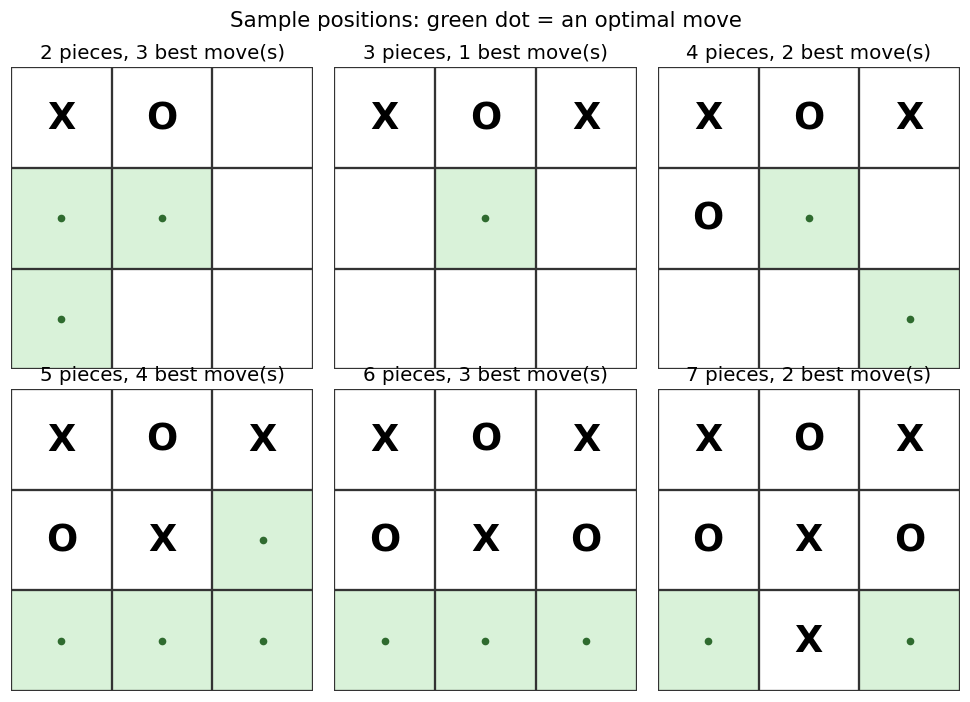

First sample board:
X O X
O . .
. . .


In [11]:
def draw_position(ax, board, optimal_moves=(), title: str = "") -> None:
    """Draw one 3x3 board; optimal cells get a pale square plus a dot."""
    symbols = {EMPTY: "", X: "X", O: "O"}
    ax.set_xlim(0, 3)
    ax.set_ylim(3, 0)  # row 0 at the top

    for index in range(9):
        row, column = divmod(index, 3)
        if index in optimal_moves:
            ax.add_patch(
                plt.Rectangle((column, row), 1, 1, facecolor="#d9f2d9", edgecolor="none", zorder=0)
            )
            ax.plot(column + 0.5, row + 0.5, marker="o", markersize=4, color="#2f6b2f", zorder=1)
        mark = symbols[board[index]]
        if mark:
            ax.text(
                column + 0.5, row + 0.5, mark,
                ha="center", va="center", fontsize=24, fontweight="bold", zorder=2,
            )

    for line in range(4):
        ax.plot([0, 3], [line, line], color="#333333", linewidth=1.5)
        ax.plot([line, line], [0, 3], color="#333333", linewidth=1.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    ax.set_title(title)
    for spine in ax.spines.values():
        spine.set_visible(False)


# One representative board per game stage (2..7 pieces already placed).
sample_indices = []
for target_pieces in (2, 3, 4, 5, 6, 7):
    chosen = next(
        index
        for index, board in enumerate(BOARDS)
        if sum(value != EMPTY for value in board) == target_pieces
    )
    sample_indices.append(chosen)

figure, axes = plt.subplots(2, 3, figsize=(9, 6.5))
for ax, index in zip(axes.flat, sample_indices):
    draw_position(
        ax,
        BOARDS[index],
        OPTIMAL_MOVES[index],
        f"{sum(value != EMPTY for value in BOARDS[index])} pieces, {len(OPTIMAL_MOVES[index])} best move(s)",
    )
figure.suptitle("Sample positions: green dot = an optimal move", fontsize=14)
figure.tight_layout()
plt.show()

print("First sample board:")
print(format_board(BOARDS[sample_indices[2]]))

## 6. A leakage-safe train / validation / test split

A random split would be misleading: rotating a training board produces a "new" board that
the model has effectively already seen. We therefore group positions by **canonical form**
and split the groups, not the boards. The 4,520 positions fall into **627** symmetry groups.

- 70% of groups → training
- 15% → validation (used to watch overfitting and to stop training)
- 15% → test (touched only for final measurements)

The asserts below stop the notebook if a canonical form appears in more than one split.

In [12]:
group_to_indices: dict[tuple[int, ...], list[int]] = defaultdict(list)
for index, board in enumerate(BOARDS):
    group_to_indices[canonical(board)].append(index)

groups = sorted(group_to_indices)
split_rng = np.random.default_rng(CONFIG["seed"])
split_rng.shuffle(groups)

n_groups = len(groups)
n_train_groups = int(CONFIG["split"]["train"] * n_groups)
n_val_groups = int(CONFIG["split"]["val"] * n_groups)

train_groups = groups[:n_train_groups]
val_groups = groups[n_train_groups : n_train_groups + n_val_groups]
test_groups = groups[n_train_groups + n_val_groups :]


def indices_for(group_list: Sequence[tuple[int, ...]]) -> np.ndarray:
    """All position indices belonging to these canonical groups."""
    return np.array(
        [index for group in group_list for index in group_to_indices[group]],
        dtype=np.int64,
    )


train_idx = indices_for(train_groups)
val_idx = indices_for(val_groups)
test_idx = indices_for(test_groups)

assert len(train_idx) + len(val_idx) + len(test_idx) == len(BOARDS)
assert set(train_groups).isdisjoint(val_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(val_groups).isdisjoint(test_groups)

print(f"Symmetry groups: {n_groups} total")
print(f"  groups  -> train {len(train_groups)}, val {len(val_groups)}, test {len(test_groups)}")
print(f"  boards  -> train {len(train_idx):,}, val {len(val_idx):,}, test {len(test_idx):,}")
print("Leakage check passed: no canonical form is shared across splits.")

Symmetry groups: 627 total
  groups  -> train 438, val 94, test 95
  boards  -> train 3,147, val 691, test 682
Leakage check passed: no canonical form is shared across splits.


**Split arrays and the memorization subset.** The next cell slices the tensors into the
three named splits and then draws the 60 training boards that the overfit model is allowed
to see. Those exact encoded boards are what `memorized_boards.json` will contain.

**Expected output:** the overfit subset size and a reminder that its boards are recorded for
the website's "seen before" tag.

In [13]:
# Slice the arrays once; every training section uses these names.
X_train, X_val, X_test = X_ALL[train_idx], X_ALL[val_idx], X_ALL[test_idx]
y_train, y_val, y_test = Y_ALL[train_idx], Y_ALL[val_idx], Y_ALL[test_idx]
opt_train, opt_val, opt_test = OPTIMAL_BOOL[train_idx], OPTIMAL_BOOL[val_idx], OPTIMAL_BOOL[test_idx]
boards_train = [BOARDS[i] for i in train_idx]
boards_val = [BOARDS[i] for i in val_idx]
boards_test = [BOARDS[i] for i in test_idx]
movers_train = MOVERS[train_idx]
movers_val = MOVERS[val_idx]
movers_test = MOVERS[test_idx]

# The overfit model sees only a small random subset of the training positions.
subset_rng = np.random.default_rng(CONFIG["seed"] + 1)
overfit_index = np.sort(
    subset_rng.choice(len(X_train), size=CONFIG["overfit_subset_size"], replace=False)
)
X_overfit, y_overfit = X_train[overfit_index], y_train[overfit_index]
opt_overfit = opt_train[overfit_index]
boards_overfit = [boards_train[i] for i in overfit_index]

assert len(X_overfit) == CONFIG["overfit_subset_size"]
print(f"Overfit model training subset: {len(X_overfit)} boards (IDs saved for the website)")

Overfit model training subset: 60 boards (IDs saved for the website)


## 7. Three CNN architectures

All three models share the same contract:

- input shape `(3, 3, 1)`, already in player-to-move perspective;
- output `Dense(9, softmax)`: one probability per cell;
- Adam optimizer and categorical cross-entropy on the soft minimax labels.

They differ only in capacity, regularization and training data, which is exactly the
comparison we want the teacher and the players to see.

| Model | Capacity | Regularization | Training data |
|---|---|---|---|
| `underfit` | one convolution with 2 filters, then a linear output | none | all training boards, 3 epochs |
| `overfit` | three convolutions (32, 64, 128 filters) plus a 512-unit dense layer | **none** | 60 training boards, 300 epochs |
| `stable` | two convolutions (32, 64 filters) plus a 128-unit dense layer | dropout 0.3, symmetry augmentation, early stopping | all training boards (×8 symmetries) |

### 7.1 Accuracy, defined the way this project uses it

Keras's built-in accuracy is not suitable here: our targets are soft distributions, and the
project defines a prediction as correct when the **highest-probability legal move** belongs
to the optimal set. The callback below computes exactly that after every epoch, so the
plotted curves and the final tables use one consistent definition. It also makes the
"illegal move" behaviour visible later, because accuracy ignores occupied cells while the
gameplay evaluation separately counts picks of occupied cells.

In [14]:
def legal_mask_from_inputs(X: np.ndarray) -> np.ndarray:
    """A cell is legal when its encoded value is zero (empty), shape (n, 9)."""
    return X.reshape(len(X), 9) == 0


def predict_probabilities(model, X: np.ndarray) -> np.ndarray:
    """Model probabilities for every cell, shape (n, 9)."""
    return model.predict(X, batch_size=1024, verbose=0).astype(np.float32)


def masked_accuracy(model, X: np.ndarray, optimal_bool: np.ndarray) -> float:
    """Fraction of boards where the best legal move is in the optimal set."""
    probabilities = predict_probabilities(model, X)
    legal = legal_mask_from_inputs(X)
    masked = np.where(legal, probabilities, -np.inf)
    chosen = masked.argmax(axis=1)
    return float(optimal_bool[np.arange(len(chosen)), chosen].mean())


class MaskedAccuracyHistory(tf.keras.callbacks.Callback):
    """Record masked train/validation accuracy after every epoch."""

    def __init__(self, X_train, opt_train, X_val, opt_val):
        super().__init__()
        self.X_train = X_train
        self.opt_train = opt_train.astype(bool)
        self.X_val = X_val
        self.opt_val = opt_val.astype(bool)
        self.legal_train = legal_mask_from_inputs(X_train)
        self.legal_val = legal_mask_from_inputs(X_val)
        self.train_accuracy: list[float] = []
        self.val_accuracy: list[float] = []

    def _score(self, X, legal, optimal) -> float:
        probabilities = predict_probabilities(self.model, X)
        chosen = np.where(legal, probabilities, -np.inf).argmax(axis=1)
        return float(optimal[np.arange(len(chosen)), chosen].mean())

    def on_epoch_end(self, epoch, logs=None):
        self.train_accuracy.append(self._score(self.X_train, self.legal_train, self.opt_train))
        self.val_accuracy.append(self._score(self.X_val, self.legal_val, self.opt_val))


def merge_history(fit_history, callback: MaskedAccuracyHistory) -> dict[str, list[float]]:
    """Combine Keras loss curves with our masked-accuracy curves."""
    return {
        "loss": [float(value) for value in fit_history.history["loss"]],
        "val_loss": [float(value) for value in fit_history.history["val_loss"]],
        "accuracy": [float(value) for value in callback.train_accuracy],
        "val_accuracy": [float(value) for value in callback.val_accuracy],
    }


def plot_training_curves(history: dict[str, list[float]], title: str, filename: str) -> None:
    """Two panels: loss and masked accuracy, train versus validation."""
    epochs = np.arange(1, len(history["loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

    axes[0].plot(epochs, history["loss"], color="#1f4e79", marker="o", markersize=3,
                 linewidth=2, label="Training")
    axes[0].plot(epochs, history["val_loss"], color="#b03a2e", linestyle="--",
                 marker="s", markersize=3, linewidth=2, label="Validation")
    axes[0].set_title("Loss: lower is better")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(epochs, history["accuracy"], color="#1f4e79", marker="o", markersize=3,
                 linewidth=2, label="Training")
    axes[1].plot(epochs, history["val_accuracy"], color="#b03a2e", linestyle="--",
                 marker="s", markersize=3, linewidth=2, label="Validation")
    axes[1].set_ylim(0, 1.02)
    axes[1].set_title("Best-legal-move accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    figure.suptitle(title, fontsize=14)
    figure.tight_layout()
    figure.savefig(PLOT_DIR / filename, bbox_inches="tight")
    plt.show()

### 7.2 The three model builders

The next cell defines one builder per level and prints every layer stack with its parameter
count. The architectures match the project specification exactly; only their capacity,
regularization and training data differ.

**Expected output:** three `model.summary()` tables. The underfit model has about 200
parameters, the overfit model has hundreds of thousands, and the stable model sits between
them.

In [15]:
def compile_model(model, learning_rate: float):
    """Shared optimizer/loss settings for all three models."""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.CategoricalCrossentropy(),
    )
    return model


def build_underfit():
    """Tiny capacity: one convolution with two filters, then a linear map to 9 cells."""
    model = tf.keras.Sequential(
        [
            keras.Input(shape=(3, 3, 1)),
            keras.layers.Conv2D(2, 3, padding="same", activation="relu", name="conv1"),
            keras.layers.Flatten(name="flatten"),
            keras.layers.Dense(9, activation="softmax", name="moves"),
        ],
        name="underfit",
    )
    return compile_model(model, CONFIG["underfit"]["learning_rate"])


def build_overfit():
    """Large capacity with no regularization: enough to memorize 60 boards."""
    model = tf.keras.Sequential(
        [
            keras.Input(shape=(3, 3, 1)),
            keras.layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
            keras.layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
            keras.layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
            keras.layers.Flatten(name="flatten"),
            keras.layers.Dense(512, activation="relu", name="dense1"),
            keras.layers.Dense(9, activation="softmax", name="moves"),
        ],
        name="overfit",
    )
    return compile_model(model, CONFIG["overfit"]["learning_rate"])


def build_stable():
    """Moderate capacity plus dropout: enough to learn rules, not enough to memorize noise."""
    model = tf.keras.Sequential(
        [
            keras.Input(shape=(3, 3, 1)),
            keras.layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
            keras.layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
            keras.layers.Flatten(name="flatten"),
            keras.layers.Dense(128, activation="relu", name="dense1"),
            keras.layers.Dropout(0.3, name="dropout"),
            keras.layers.Dense(9, activation="softmax", name="moves"),
        ],
        name="stable",
    )
    return compile_model(model, CONFIG["stable"]["learning_rate"])


MODELS = {
    "underfit": build_underfit(),
    "overfit": build_overfit(),
    "stable": build_stable(),
}
for model_name, model in MODELS.items():
    print(f"\n{model_name.upper()} — {model.count_params():,} parameters")
    model.summary()


UNDERFIT — 191 parameters

Model: "underfit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 3, 3, 2)        │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moves (Dense)                   │ (None, 9)              │           171 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191 (764.00 B)

 Trainable params: 191 (764.00 B)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 3, 3, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 3, 3, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moves (Dense)                   │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,833 (366.54 KB)

 Trainable params: 93,833 (366.54 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Training the underfit model

The underfit model is intentionally too small (two filters) and trained for only three
epochs with a very low learning rate. It is not a bug: it is the control condition that
shows what happens when a model does not get enough capacity or practice.

**Expected output:** the loss stays high and both training and validation accuracy remain
low, with only a small gap between them. That is underfitting: the model is weak everywhere,
not just on new boards.

Training time: 1.4 s
Final training accuracy  : 55.1%
Final validation accuracy: 56.0%


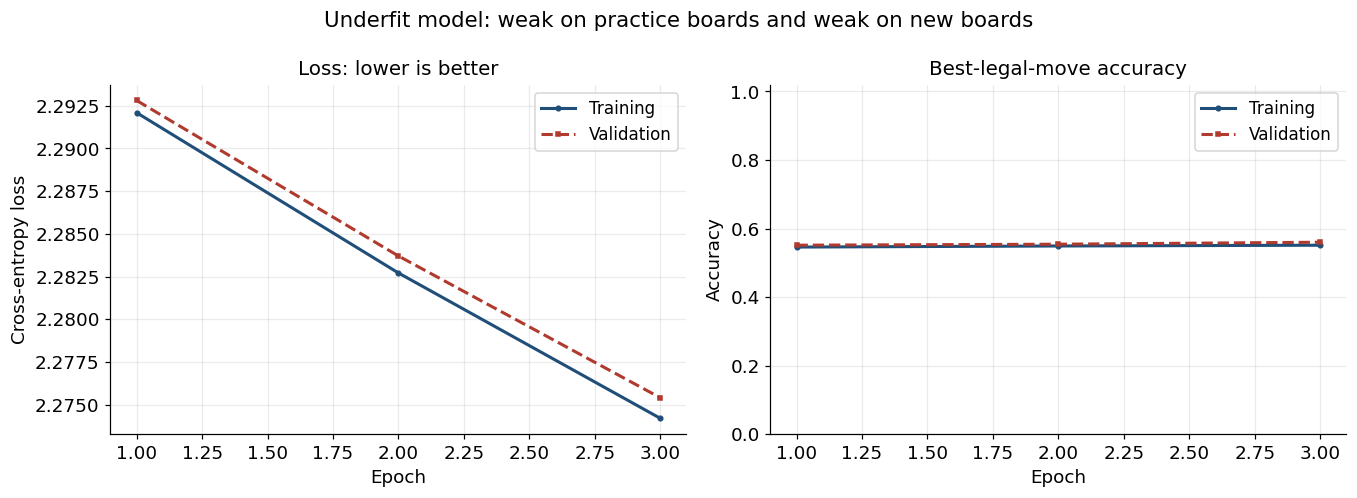

In [16]:
start = time.time()
underfit_callback = MaskedAccuracyHistory(X_train, opt_train, X_val, opt_val)
underfit_fit = MODELS["underfit"].fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=CONFIG["underfit"]["epochs"],
    batch_size=CONFIG["underfit"]["batch_size"],
    verbose=0,
    callbacks=[underfit_callback],
)
underfit_seconds = time.time() - start
history_underfit = merge_history(underfit_fit, underfit_callback)

print(f"Training time: {underfit_seconds:.1f} s")
print(f"Final training accuracy  : {history_underfit['accuracy'][-1]:.1%}")
print(f"Final validation accuracy: {history_underfit['val_accuracy'][-1]:.1%}")

plot_training_curves(
    history_underfit,
    "Underfit model: weak on practice boards and weak on new boards",
    "curves_underfit.png",
)

**Takeaway.** Both curves stay low. This model has not learned enough even about the
boards it practiced on, so it also has no chance on new ones. That is underfitting, not
overfitting: adding more data would not help until the model is given more capacity or
more training.

## 9. Training the overfit model

This model is deliberately given more capacity than the task needs, **no** dropout, no
weight decay, no augmentation and no early stopping. It sees only 60 training boards and
trains on them for 300 epochs.

**Expected output:** training accuracy climbs to (almost) 100%, while validation accuracy
stays far lower. The gap between the two curves is the visual definition of overfitting.
The exact 60 boards are recorded so the website can later say "I have seen this board
before".

Training time: 70.0 s
Final training accuracy  : 100.0%
Final validation accuracy: 73.8%
Train - validation gap   : 26.2%


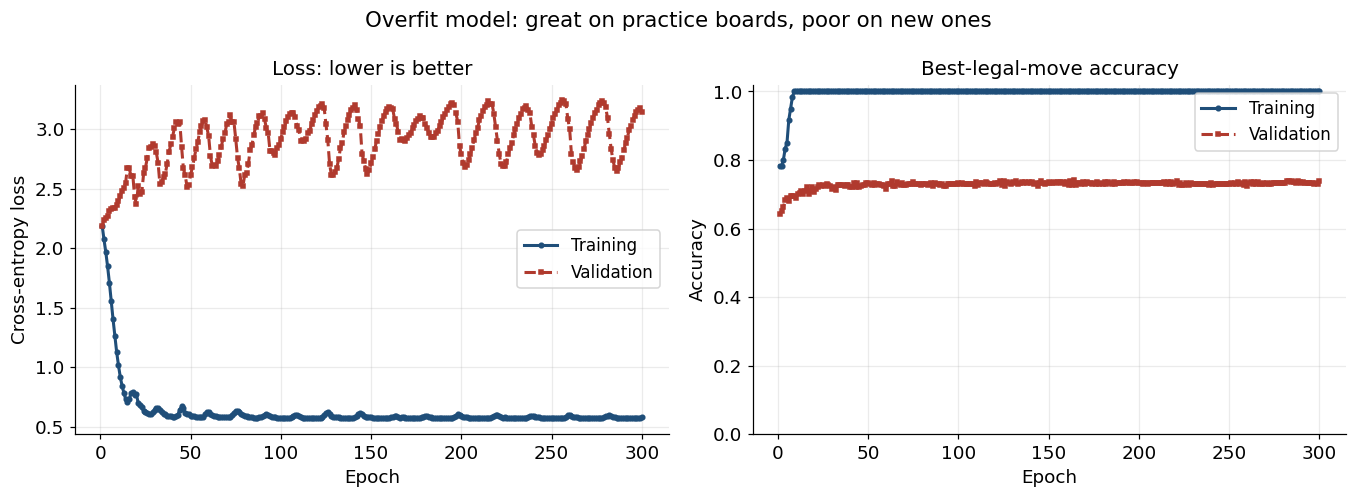

In [17]:
start = time.time()
overfit_callback = MaskedAccuracyHistory(X_overfit, opt_overfit, X_val, opt_val)
overfit_fit = MODELS["overfit"].fit(
    X_overfit,
    y_overfit,
    validation_data=(X_val, y_val),
    epochs=CONFIG["overfit"]["epochs"],
    batch_size=CONFIG["overfit"]["batch_size"],
    verbose=0,
    callbacks=[overfit_callback],
)
overfit_seconds = time.time() - start
history_overfit = merge_history(overfit_fit, overfit_callback)

overfit_gap = history_overfit["accuracy"][-1] - history_overfit["val_accuracy"][-1]
print(f"Training time: {overfit_seconds:.1f} s")
print(f"Final training accuracy  : {history_overfit['accuracy'][-1]:.1%}")
print(f"Final validation accuracy: {history_overfit['val_accuracy'][-1]:.1%}")
print(f"Train - validation gap   : {overfit_gap:.1%}")

plot_training_curves(
    history_overfit,
    "Overfit model: great on practice boards, poor on new ones",
    "curves_overfit.png",
)

**Takeaway.** The training curve reaches the top while the validation curve does not
follow. The model memorized 60 specific boards instead of learning rules that transfer.
When a player makes a move the model has never seen, its answer has no reason to be good.

## 10. Training the stable model

The stable model gets the right tools for generalization:

1. **All training boards × all 8 symmetries.** A rotated or mirrored board now looks like
   a new example, so the model cannot simply memorize one orientation.
2. **Dropout (30%).** During training, random units are switched off, which prevents the
   network from relying on one fragile path.
3. **Early stopping.** Training watches validation loss and restores the best epoch. It
   stops if validation does not improve for 8 epochs.

**Expected output:** training and validation accuracy rise together and end close to each
other, with a much smaller gap than the overfit model. This is what good generalization
looks like.

The accuracy callback is evaluated on the original (not augmented) training boards, so the
training curve remains comparable with the other two models.

In [18]:
def augment_with_symmetries(X: np.ndarray, y: np.ndarray, optimal_bool: np.ndarray):
    """Return the 8 symmetric versions of every board, with labels transformed identically."""
    flat = X.reshape(len(X), 9)
    X_augmented = np.concatenate(
        [flat[:, list(perm)] for perm in SYMMETRY_PERMS], axis=0
    ).reshape(-1, 3, 3, 1)
    y_augmented = np.concatenate([y[:, list(perm)] for perm in SYMMETRY_PERMS], axis=0)
    optimal_augmented = np.concatenate(
        [optimal_bool[:, list(perm)] for perm in SYMMETRY_PERMS], axis=0
    )
    return X_augmented, y_augmented, optimal_augmented


X_train_aug, y_train_aug, opt_train_aug = augment_with_symmetries(
    X_train, y_train, opt_train
)
assert len(X_train_aug) == 8 * len(X_train)
assert np.allclose(y_train_aug.sum(axis=1), 1.0)
print(f"Augmented training set: {len(X_train):,} boards × 8 = {len(X_train_aug):,} examples")

Augmented training set: 3,147 boards × 8 = 25,176 examples


**Training run.** The next cell trains on the augmented set, records masked accuracy every
epoch and restores the weights from the epoch with the lowest validation loss.

**Expected output:** training time, best epoch, final train/validation accuracy, and the two
curves rising together and staying close.

Training time: 22.9 s (21 epochs)
Best epoch (lowest validation loss): 11
Final training accuracy  : 100.0%
Final validation accuracy: 97.8%


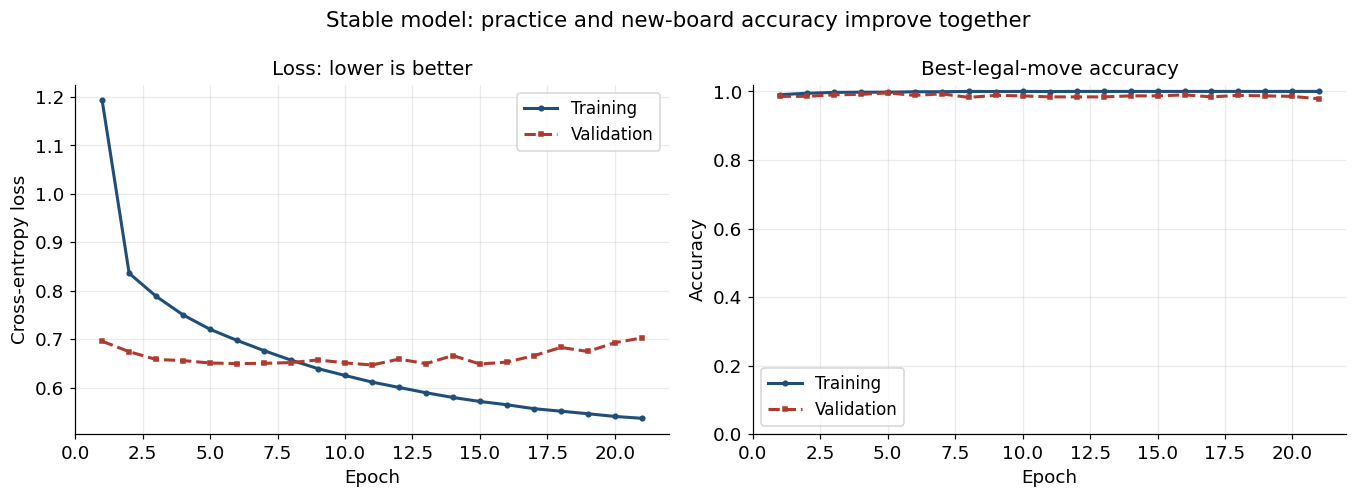

In [19]:
start = time.time()
stable_callback = MaskedAccuracyHistory(X_train, opt_train, X_val, opt_val)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=CONFIG["stable"]["early_stopping_patience"],
    restore_best_weights=True,
    verbose=0,
)
stable_fit = MODELS["stable"].fit(
    X_train_aug,
    y_train_aug,
    validation_data=(X_val, y_val),
    epochs=CONFIG["stable"]["epochs"],
    batch_size=CONFIG["stable"]["batch_size"],
    verbose=0,
    callbacks=[stable_callback, early_stopping],
)
stable_seconds = time.time() - start
history_stable = merge_history(stable_fit, stable_callback)

best_epoch = int(np.argmin(history_stable["val_loss"])) + 1
print(f"Training time: {stable_seconds:.1f} s ({len(history_stable['loss'])} epochs)")
print(f"Best epoch (lowest validation loss): {best_epoch}")
print(f"Final training accuracy  : {history_stable['accuracy'][-1]:.1%}")
print(f"Final validation accuracy: {history_stable['val_accuracy'][-1]:.1%}")

plot_training_curves(
    history_stable,
    "Stable model: practice and new-board accuracy improve together",
    "curves_stable.png",
)

**Takeaway.** Symmetry augmentation makes every rule visible from eight angles, dropout
keeps the network from relying on fragile memorized paths, and early stopping keeps the
best-generalizing weights. The two curves stay close, which is the signature of
generalization.

## 11. Side-by-side comparison

Now that all three models are trained, we measure the same three quantities for each one:
accuracy on the boards it actually practiced on, on the validation boards and on the
untouched test boards. The overfit model's practice set is its 60-board subset, so its
training number reflects what it memorized rather than the whole training split. The test
column is the honest one: those boards played no part in training, model selection or early
stopping.

Two figures are produced:

- a grouped bar chart of train / validation / test accuracy;
- an overlay of the validation curves, so the underfit, overfit and stable behaviours can be
  compared on one axis.

In [20]:
HISTORIES = {
    "underfit": history_underfit,
    "overfit": history_overfit,
    "stable": history_stable,
}
TRAINING_SECONDS = {
    "underfit": underfit_seconds,
    "overfit": overfit_seconds,
    "stable": stable_seconds,
}
MODEL_NAMES = ["underfit", "overfit", "stable"]

# Each model is judged on the practice set it actually saw. The overfit model
# deliberately saw only its 60-board subset, so using the whole training split
# would understate what it memorized and hide the very effect we are teaching.
TRAIN_EVAL = {
    "underfit": (X_train, y_train, opt_train),
    "overfit": (X_overfit, y_overfit, opt_overfit),
    "stable": (X_train, y_train, opt_train),
}

METRICS: dict[str, dict[str, float]] = {}
for name in MODEL_NAMES:
    model = MODELS[name]
    X_seen, y_seen, opt_seen = TRAIN_EVAL[name]
    train_loss = float(model.evaluate(X_seen, y_seen, verbose=0))
    val_loss = float(model.evaluate(X_val, y_val, verbose=0))
    METRICS[name] = {
        "train_acc": masked_accuracy(model, X_seen, opt_seen),
        "val_acc": masked_accuracy(model, X_val, opt_val),
        "test_acc": masked_accuracy(model, X_test, opt_test),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "params": int(model.count_params()),
    }
    print(
        f"{name:9s}: train {METRICS[name]['train_acc']:.1%} | "
        f"val {METRICS[name]['val_acc']:.1%} | test {METRICS[name]['test_acc']:.1%}"
    )

underfit : train 55.1% | val 56.0% | test 55.6%


overfit  : train 100.0% | val 73.8% | test 74.6%


stable   : train 100.0% | val 98.4% | test 95.9%


**Results table.** The next cell formats the same numbers as a table, including the gap
between training and test accuracy. A large gap is the quantitative signature of
memorization; a small gap with high accuracy is generalization.

**Expected output:** a three-row table rendered as Markdown.

In [21]:
from IPython.display import Markdown, display

table_lines = [
    "| Model | Parameters | Train accuracy (practice set) | Validation accuracy | Test accuracy | Test gap vs train |",
    "|---|---:|---:|---:|---:|---:|",
]
for name in MODEL_NAMES:
    row = METRICS[name]
    gap = row["train_acc"] - row["test_acc"]
    table_lines.append(
        f"| `{name}` | {row['params']:,} | {row['train_acc']:.1%} | "
        f"{row['val_acc']:.1%} | {row['test_acc']:.1%} | {gap:+.1%} |"
    )
display(Markdown("\n".join(table_lines)))

| Model | Parameters | Train accuracy (practice set) | Validation accuracy | Test accuracy | Test gap vs train |
|---|---:|---:|---:|---:|---:|
| `underfit` | 191 | 55.1% | 56.0% | 55.6% | -0.4% |
| `overfit` | 687,625 | 100.0% | 73.8% | 74.6% | +25.4% |
| `stable` | 93,833 | 100.0% | 98.4% | 95.9% | +4.1% |

**Accuracy chart.** The next cell draws the table as grouped bars, so the size of the
train-to-test drop is visible at a glance. Hatches and printed percentages keep the chart
readable without relying on colour alone.

**Expected output:** one figure saved as `plots/accuracy_comparison.png`.

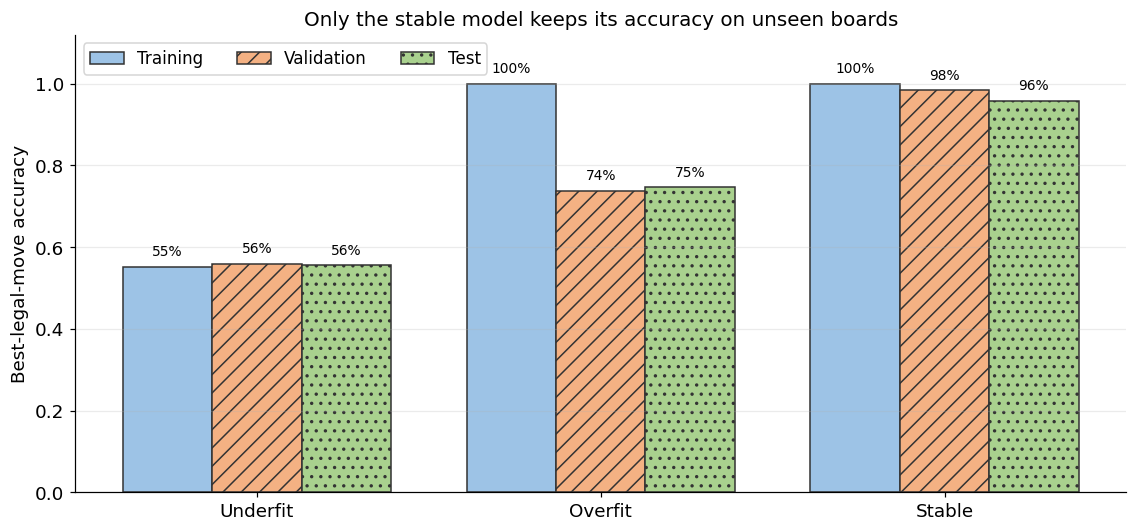

In [22]:
splits = ["train_acc", "val_acc", "test_acc"]
split_labels = ["Training", "Validation", "Test"]
colours = {"train_acc": "#9dc3e6", "val_acc": "#f4b183", "test_acc": "#a9d18e"}
hatches = {"train_acc": "", "val_acc": "//", "test_acc": ".."}

x = np.arange(len(MODEL_NAMES))
width = 0.26
figure, ax = plt.subplots(figsize=(10.5, 5.0))
for offset, split in enumerate(splits):
    values = [METRICS[name][split] for name in MODEL_NAMES]
    bars = ax.bar(
        x + (offset - 1) * width,
        values,
        width,
        label=split_labels[offset],
        color=colours[split],
        edgecolor="#333333",
        hatch=hatches[split],
    )
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.0%}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

ax.set_xticks(x, [name.title() for name in MODEL_NAMES])
ax.set_ylim(0, 1.12)
ax.set_ylabel("Best-legal-move accuracy")
ax.set_title("Only the stable model keeps its accuracy on unseen boards")
ax.legend(loc="upper left", ncols=3)
ax.grid(axis="y", alpha=0.25)
figure.tight_layout()
figure.savefig(PLOT_DIR / "accuracy_comparison.png", bbox_inches="tight")
plt.show()

**Training-curve overlay.** The next cell puts the validation curves of all three models on
the same axes. The overfit model's validation loss eventually rises while the stable model's
stays low; the underfit model never reaches a good value at all.

**Expected output:** one two-panel figure saved as `plots/validation_curves_overlay.png`.

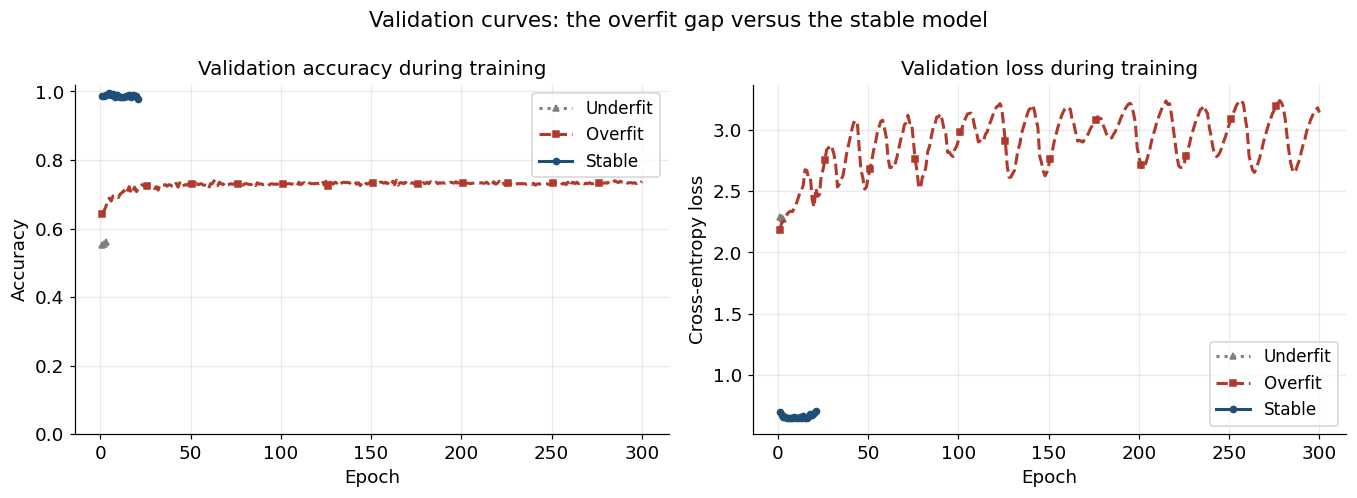

In [23]:
styles = {
    "underfit": {"linestyle": ":", "color": "#7f7f7f", "marker": "^"},
    "overfit": {"linestyle": "--", "color": "#b03a2e", "marker": "s"},
    "stable": {"linestyle": "-", "color": "#1f4e79", "marker": "o"},
}

figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for name in MODEL_NAMES:
    history = HISTORIES[name]
    epochs = np.arange(1, len(history["val_accuracy"]) + 1)
    style = styles[name]
    marker_every = max(1, len(epochs) // 12)
    axes[0].plot(
        epochs, history["val_accuracy"], label=name.title(),
        markevery=marker_every, markersize=4, linewidth=2, **style,
    )
    axes[1].plot(
        epochs, history["val_loss"], label=name.title(),
        markevery=marker_every, markersize=4, linewidth=2, **style,
    )

axes[0].set_ylim(0, 1.02)
axes[0].set_title("Validation accuracy during training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].set_title("Validation loss during training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.25)

figure.suptitle("Validation curves: the overfit gap versus the stable model", fontsize=14)
figure.tight_layout()
figure.savefig(PLOT_DIR / "validation_curves_overlay.png", bbox_inches="tight")
plt.show()

## 12. Game-play evaluation

Accuracy on stored boards is useful, but the real product is a game. Each model now plays:

- **1,000 games against a random player** (500 as X, 500 as O);
- **200 games against perfect minimax** (100 as X, 100 as O).

The AI always chooses the highest-probability **legal** cell. Two extra numbers tell the
teaching story:

- **illegal-move rate before masking**: how often the raw argmax pointed at an occupied cell
  (the underfit model is expected to do this often);
- **missed-win rate** and **missed-block rate**: how often the AI had an immediate winning
  move and did not take it, or had to block the opponent's immediate win and did not.

A "block chance" is counted only when the AI has no immediate win of its own. If the opponent
has two winning threats at once, no single move can block both, so the turn is counted as a
missed block.

The games use the same mover-perspective encoding as training. The minimax opponent chooses
randomly among equally optimal moves so that 200 games are not just two repeated games.

In [24]:
def immediate_wins(board, player: int) -> list[int]:
    """Moves that win immediately for `player`."""
    return [
        move
        for move in legal_moves(board)
        if winner(play(board, move, player)) == player
    ]


def model_probabilities(model, board, player: int, cache: Optional[dict] = None) -> np.ndarray:
    """One forward pass for one board, in the player's perspective.

    `cache` is optional and only used during game simulation. Many of the 1,200 games
    revisit the same position, so remembering its probabilities keeps the notebook fast
    without changing any answer.
    """
    if cache is not None:
        key = (tuple(int(value) for value in board), int(player))
        if key in cache:
            return cache[key]
    x = to_mover_perspective(board, player)[None, ...]
    probabilities = model(x, training=False).numpy()[0].astype(np.float32)
    if cache is not None:
        cache[key] = probabilities
    return probabilities


def masked_choice(board, probabilities: np.ndarray) -> int:
    """Highest-probability legal cell."""
    legal = np.array([cell == EMPTY for cell in board], dtype=bool)
    return int(np.where(legal, probabilities, -np.inf).argmax())


def choose_model_move(model, board, player: int, cache: Optional[dict] = None):
    """Return (legal masked choice, all probabilities, raw argmax was occupied)."""
    probabilities = model_probabilities(model, board, player, cache=cache)
    chosen = masked_choice(board, probabilities)
    picked_occupied = board[int(np.argmax(probabilities))] != EMPTY
    return chosen, probabilities, picked_occupied

### 12.1 One game, with teaching statistics

The next cell plays one complete game. On every turn it records whether the AI had an
immediate win and missed it, whether it faced an immediate threat and failed to block it,
and whether the unmasked argmax pointed at an occupied cell: the game has started.

**Expected output:** no printed output; it defines the function used by the batch runner.

In [25]:
def play_episode(model, opponent: str, model_player: int, rng,
                 cache: Optional[dict] = None) -> tuple[str, dict[str, int]]:
    """Play one game and collect outcome plus teaching statistics for the model."""
    board = (EMPTY,) * 9
    player = X
    stats = {
        "model_moves": 0,
        "illegal": 0,
        "win_chances": 0,
        "missed_wins": 0,
        "block_chances": 0,
        "missed_blocks": 0,
    }

    while True:
        champion = winner(board)
        if champion is not None:
            outcome = "win" if champion == model_player else "loss"
            break
        if is_full(board):
            outcome = "draw"
            break

        if player == model_player:
            winning_now = immediate_wins(board, player)
            threats = immediate_wins(board, other(player))
            move, _, picked_occupied = choose_model_move(model, board, player, cache=cache)

            stats["model_moves"] += 1
            stats["illegal"] += int(picked_occupied)

            if winning_now:
                stats["win_chances"] += 1
                if move not in winning_now:
                    stats["missed_wins"] += 1
            elif threats:
                stats["block_chances"] += 1
                if not (len(threats) == 1 and move == threats[0]):
                    stats["missed_blocks"] += 1
        elif opponent == "random":
            move = int(rng.choice(legal_moves(board)))
        else:
            _, optimal = minimax(board, player)
            move = int(rng.choice(optimal))

        board = play(board, move, player)
        player = other(player)

    return outcome, stats

### 12.2 Batch evaluation

The next cell repeats the game 1,000 times against a random opponent and 200 times against
minimax, alternating the AI between X and O. All results are kept in one dictionary that is
later written to `gameplay_results.json`.

**Expected output:** one `finished` line per model; the full table is printed next.

In [26]:
def evaluate_games(model_name: str, opponent: str, games: int, seed_offset: int,
                   cache: Optional[dict] = None) -> dict:
    """Run a batch of games and return win/draw/loss counts and rates."""
    rng = np.random.default_rng(CONFIG["seed"] + seed_offset)
    tally = Counter()
    totals = Counter()

    for game_index in range(games):
        model_player = X if game_index % 2 == 0 else O
        outcome, stats = play_episode(
            MODELS[model_name], opponent, model_player, rng, cache=cache
        )
        tally[outcome] += 1
        for key, value in stats.items():
            totals[key] += value

    result = {
        "games": games,
        "wins": tally["win"],
        "draws": tally["draw"],
        "losses": tally["loss"],
        "model_moves": totals["model_moves"],
        "illegal": totals["illegal"],
        "win_chances": totals["win_chances"],
        "missed_wins": totals["missed_wins"],
        "block_chances": totals["block_chances"],
        "missed_blocks": totals["missed_blocks"],
    }
    result["illegal_rate"] = result["illegal"] / max(result["model_moves"], 1)
    result["missed_win_rate"] = result["missed_wins"] / max(result["win_chances"], 1)
    result["missed_block_rate"] = result["missed_blocks"] / max(result["block_chances"], 1)
    return result


def combine_results(first: dict, second: dict) -> dict:
    """Merge two opponent results into the overall rates stored in metrics.json."""
    keys = [
        "games", "wins", "draws", "losses", "model_moves", "illegal",
        "win_chances", "missed_wins", "block_chances", "missed_blocks",
    ]
    combined = {key: first[key] + second[key] for key in keys}
    combined["illegal_rate"] = combined["illegal"] / max(combined["model_moves"], 1)
    combined["missed_win_rate"] = combined["missed_wins"] / max(combined["win_chances"], 1)
    combined["missed_block_rate"] = combined["missed_blocks"] / max(combined["block_chances"], 1)
    return combined


GAMEPLAY: dict[str, dict] = {}
PROBABILITY_CACHES = {name: {} for name in MODEL_NAMES}
for model_index, name in enumerate(MODEL_NAMES):
    vs_random = evaluate_games(
        name, "random", CONFIG["games"]["vs_random"], 100 + model_index * 20,
        cache=PROBABILITY_CACHES[name],
    )
    vs_minimax = evaluate_games(
        name, "minimax", CONFIG["games"]["vs_minimax"], 500 + model_index * 20,
        cache=PROBABILITY_CACHES[name],
    )
    GAMEPLAY[name] = {
        "random": vs_random,
        "minimax": vs_minimax,
        "overall": combine_results(vs_random, vs_minimax),
    }
    print(f"{name} finished ({vs_random['games']} + {vs_minimax['games']} games)")

underfit finished (1000 + 200 games)


overfit finished (1000 + 200 games)


stable finished (1000 + 200 games)


**Results table.** The next cell prints win, draw and loss shares for every model and
opponent, together with the missed-win, missed-block and illegal-move rates. These are the
numbers quoted in the explanations and acceptance checks.

**Expected output:** six rows, one per model and opponent.

In [27]:
print(f"{'Model':10s} {'Opponent':9s} {'Win':>6s} {'Draw':>6s} {'Loss':>6s} "
      f"{'Miss win':>9s} {'Miss block':>11s} {'Illegal':>8s}")
for name in MODEL_NAMES:
    for opponent in ("random", "minimax"):
        row = GAMEPLAY[name][opponent]
        print(
            f"{name:10s} {opponent:9s} "
            f"{row['wins'] / row['games']:6.1%} "
            f"{row['draws'] / row['games']:6.1%} "
            f"{row['losses'] / row['games']:6.1%} "
            f"{row['missed_win_rate']:9.1%} "
            f"{row['missed_block_rate']:11.1%} "
            f"{row['illegal_rate']:8.1%}"
        )

Model      Opponent     Win   Draw   Loss  Miss win  Miss block  Illegal
underfit   random     50.0%  10.8%  39.2%     62.5%       84.9%    49.4%
underfit   minimax     0.0%   0.5%  99.5%      0.0%       97.7%    36.8%
overfit    random     70.7%  10.4%  18.9%     33.7%       63.8%    18.5%
overfit    minimax     0.0%  26.0%  74.0%      0.0%       75.3%    31.4%
stable     random     92.4%   6.0%   1.6%     16.2%        8.1%     0.0%
stable     minimax     0.0%  86.5%  13.5%      0.0%       13.5%     0.0%


**Win/draw/loss chart.** The next cell turns the table into two stacked bars, one per
opponent. A stable model should have a green block with no red, an overfit model should mix
all three, and the underfit model should show visible red.

**Expected output:** one figure saved as `plots/gameplay_wdl.png`.

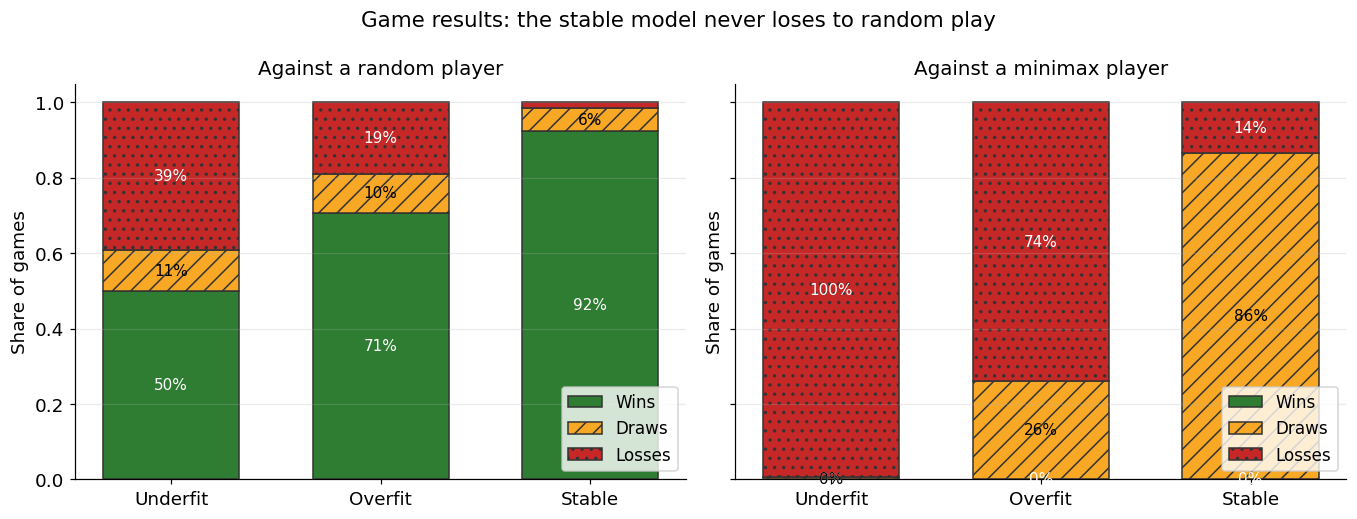

In [28]:
figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for ax, opponent in zip(axes, ("random", "minimax")):
    x = np.arange(len(MODEL_NAMES))
    wins = np.array([GAMEPLAY[name][opponent]["wins"] / GAMEPLAY[name][opponent]["games"] for name in MODEL_NAMES])
    draws = np.array([GAMEPLAY[name][opponent]["draws"] / GAMEPLAY[name][opponent]["games"] for name in MODEL_NAMES])
    losses = np.array([GAMEPLAY[name][opponent]["losses"] / GAMEPLAY[name][opponent]["games"] for name in MODEL_NAMES])

    ax.bar(x, wins, 0.65, label="Wins", color="#2e7d32", edgecolor="#333333")
    ax.bar(x, draws, 0.65, bottom=wins, label="Draws", color="#f9a825", edgecolor="#333333", hatch="//")
    ax.bar(x, losses, 0.65, bottom=wins + draws, label="Losses", color="#c62828", edgecolor="#333333", hatch="..")

    for index, name in enumerate(MODEL_NAMES):
        ax.text(index, wins[index] / 2, f"{wins[index]:.0%}", ha="center", va="center", color="white", fontsize=10)
        ax.text(index, wins[index] + draws[index] / 2, f"{draws[index]:.0%}", ha="center", va="center", fontsize=10)
        if losses[index] > 0.03:
            ax.text(index, wins[index] + draws[index] + losses[index] / 2, f"{losses[index]:.0%}", ha="center", va="center", color="white", fontsize=10)

    ax.set_xticks(x, [name.title() for name in MODEL_NAMES])
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Against a {opponent} player")
    ax.set_ylabel("Share of games")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right")

figure.suptitle("Game results: the stable model never loses to random play", fontsize=14)
figure.tight_layout()
figure.savefig(PLOT_DIR / "gameplay_wdl.png", bbox_inches="tight")
plt.show()

## 13. Seen versus unseen boards (the overfitting visual)

The most convincing demonstration of overfitting is two boards that look almost identical,
where the model is excellent on one and lost on the other. We search the overfit model's 60
memorized boards for a position that it gets right, then shift one piece to an empty
cell (preserving turn and validity). The nearby board was never in its training set and must be handled by generalization.

The heatmap shows the probability the model gives each empty cell; occupied cells are greyed
out. The chosen move is outlined in red, and every probability is printed so the figure does
not depend on colour alone.

In [29]:
def draw_probability_heatmap(ax, probabilities, board, chosen: int, title: str = ""):
    """Draw the 3x3 probability map with the chosen legal move outlined."""
    grid = probabilities.reshape(3, 3)
    occupied = np.array(board).reshape(3, 3) != EMPTY
    shown = np.ma.masked_where(occupied, grid)

    cmap = plt.cm.Blues.copy()
    cmap.set_bad("#e6e6e6")
    image = ax.imshow(shown, cmap=cmap, vmin=0, vmax=1)

    symbols = {X: "X", O: "O"}
    for index in range(9):
        row, column = divmod(index, 3)
        if occupied[row, column]:
            ax.text(column, row, symbols[board[index]], ha="center", va="center",
                    fontsize=20, fontweight="bold", color="#444444")
        else:
            ax.text(column, row, f"{grid[row, column]:.2f}", ha="center", va="center",
                    fontsize=10, color="black" if grid[row, column] < 0.6 else "white")

    chosen_row, chosen_column = divmod(chosen, 3)
    ax.add_patch(
        plt.Rectangle(
            (chosen_column - 0.5, chosen_row - 0.5), 1, 1,
            fill=False, edgecolor="#c00000", linewidth=3,
        )
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=11)
    return image


memorized_inputs = {tuple(int(v) for v in x.reshape(9)) for x in X_overfit}
position_set = set(BOARDS)
overfit_model = MODELS["overfit"]

seen_board = unseen_board = None
seen_choice = unseen_choice = None
seen_optimal = unseen_optimal = None
seen_probabilities = unseen_probabilities = None

# Strategy 1: Find a memorized board that the model gets right,
# and shift one piece to an empty cell (creating a reachable unseen board with same piece count)
# where the overfit model fails.
for local_index, board in enumerate(boards_overfit):
    if not (4 <= sum(cell != EMPTY for cell in board) <= 6):
        continue
    player = int(movers_train[overfit_index[local_index]])
    optimal = {i for i, value in enumerate(opt_overfit[local_index]) if value}
    if len(optimal) != 1:  # keep the demonstration unambiguous
        continue

    probabilities = model_probabilities(overfit_model, board, player)
    choice = masked_choice(board, probabilities)
    if choice not in optimal:
        continue

    occupied = [idx for idx, cell in enumerate(board) if cell != EMPTY]
    empty = legal_moves(board)
    found = False
    for src in occupied:
        for dst in empty:
            candidate = list(board)
            candidate[src] = EMPTY
            candidate[dst] = board[src]
            candidate = tuple(candidate)
            if candidate not in position_set or is_terminal(candidate):
                continue
            candidate_input = tuple(
                int(v) for v in to_mover_perspective(candidate, player).reshape(9)
            )
            if candidate_input in memorized_inputs:  # must be truly unseen
                continue

            candidate_optimal = set(minimax(candidate, player)[1])
            candidate_probabilities = model_probabilities(overfit_model, candidate, player)
            candidate_choice = masked_choice(candidate, candidate_probabilities)
            if candidate_choice in candidate_optimal:
                continue  # we need a visible failure

            seen_board, unseen_board = board, candidate
            seen_choice, unseen_choice = choice, candidate_choice
            seen_optimal, unseen_optimal = optimal, candidate_optimal
            seen_probabilities, unseen_probabilities = probabilities, candidate_probabilities
            found = True
            break
        if found:
            break

    if seen_board is not None:
        break

# Strategy 2 (Fallback): Match a correct memorized board with a failed unseen test board
if seen_board is None:
    for t_idx, board in enumerate(boards_test):
        if sum(cell != EMPTY for cell in board) in (4, 5, 6):
            t_player = int(movers_test[t_idx])
            t_opt = set(OPTIMAL_MOVES[int(test_idx[t_idx])])
            t_probs = model_probabilities(overfit_model, board, t_player)
            t_choice = masked_choice(board, t_probs)
            if t_choice not in t_opt:
                for local_index, s_board in enumerate(boards_overfit):
                    s_player = int(movers_train[overfit_index[local_index]])
                    s_opt = {i for i, value in enumerate(opt_overfit[local_index]) if value}
                    s_probs = model_probabilities(overfit_model, s_board, s_player)
                    s_choice = masked_choice(s_board, s_probs)
                    if s_choice in s_opt:
                        seen_board, unseen_board = s_board, board
                        seen_choice, unseen_choice = s_choice, t_choice
                        seen_optimal, unseen_optimal = s_opt, t_opt
                        seen_probabilities, unseen_probabilities = s_probs, t_probs
                        break
                if seen_board is not None:
                    break

assert seen_board is not None, "No seen/unseen contrast was found; inspect the overfit model."

print("SEEN (used in training):")
print(format_board(seen_board))
print(f"model picks {seen_choice}; optimal {sorted(seen_optimal)} -> correct\n")

print("UNSEEN (one piece shifted / unseen board, never trained on):")
print(format_board(unseen_board))
print(f"model picks {unseen_choice}; optimal {sorted(unseen_optimal)} -> wrong")

SEEN (used in training):
. . X
. X O
O . X
model picks 0; optimal [0] -> correct

UNSEEN (one piece shifted / unseen board, never trained on):
. . .
X X O
O . X
model picks 7; optimal [0] -> wrong


**The visual comparison.** The next cell draws both boards side by side with the same
probability colour scale. Read the printed numbers as well as the colours: the memorized
board should be confident and correct, the nearby new board less so.

**Expected output:** one figure saved as `plots/seen_vs_unseen_overfit.png`.

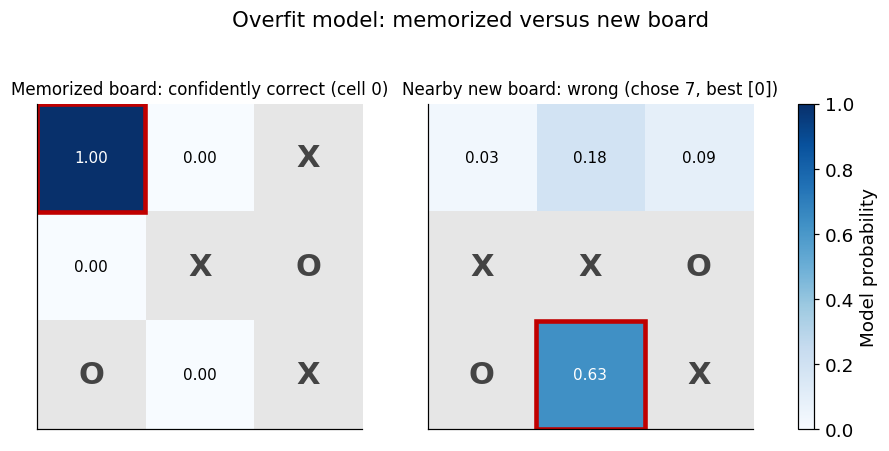

In [30]:
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.8))
image = draw_probability_heatmap(
    axes[0], seen_probabilities, seen_board, seen_choice,
    f"Memorized board: confidently correct (cell {seen_choice})",
)
draw_probability_heatmap(
    axes[1], unseen_probabilities, unseen_board, unseen_choice,
    f"Nearby new board: wrong (chose {unseen_choice}, best {sorted(unseen_optimal)})",
)
figure.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="Model probability")
figure.suptitle("Overfit model: memorized versus new board", fontsize=14)
figure.savefig(PLOT_DIR / "seen_vs_unseen_overfit.png", bbox_inches="tight")
plt.show()

## 14. Explain-a-move helper

`explain_move(model, board, player)` returns the model's nine probabilities and draws the
3×3 heatmap with the chosen legal cell outlined. This is the function the website will call
for every move in the post-game timeline.

To make the comparison concrete, the same mid-game test board is passed to all three models.
The board was not used for training, so none of the answers can come from memorization.

Test board (optimal move(s): [4]):
O X .
. . X
. . O
underfit  -> cell 6 (not optimal); top probability 0.15
overfit   -> cell 4 (wise); top probability 0.66
stable    -> cell 4 (wise); top probability 0.99


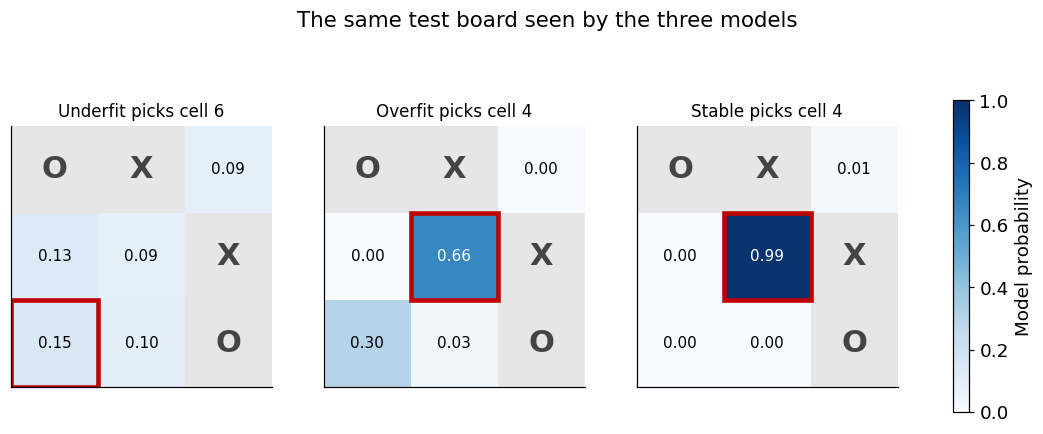

In [31]:
def explain_move(model, board, player: int, label: str = "", ax=None, show: bool = True):
    """Return probabilities and chosen cell, and draw the highlighted heatmap."""
    probabilities = model_probabilities(model, board, player)
    chosen = masked_choice(board, probabilities)

    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    image = draw_probability_heatmap(
        ax, probabilities, board, chosen, f"{label}picks cell {chosen}"
    )
    if show:
        plt.colorbar(image, ax=ax, shrink=0.8, label="Probability")
        plt.show()
    return probabilities, chosen


# A four-piece test board with exactly one optimal move.
demo_index = next(
    index
    for index in range(len(X_test))
    if sum(cell != EMPTY for cell in boards_test[index]) == 4 and opt_test[index].sum() == 1
)
demo_board = boards_test[demo_index]
demo_player = int(movers_test[demo_index])
demo_optimal = set(OPTIMAL_MOVES[int(test_idx[demo_index])])

print(f"Test board (optimal move(s): {sorted(demo_optimal)}):")
print(format_board(demo_board))

figure, axes = plt.subplots(1, 3, figsize=(13.0, 4.6))
images = []
for ax, name in zip(axes, MODEL_NAMES):
    probabilities, chosen = explain_move(
        MODELS[name], demo_board, demo_player,
        label=f"{name.title()} ", ax=ax, show=False,
    )
    images.append(ax.images[-1])
    verdict = "wise" if chosen in demo_optimal else "not optimal"
    print(f"{name:9s} -> cell {chosen} ({verdict}); top probability {probabilities[chosen]:.2f}")

figure.colorbar(images[-1], ax=axes.ravel().tolist(), shrink=0.8, label="Model probability")
figure.suptitle("The same test board seen by the three models", fontsize=14)
figure.savefig(PLOT_DIR / "heatmaps_same_board.png", bbox_inches="tight")
plt.show()

## 15. Plain-language explanations

The website must explain each model to a visitor who has never studied machine learning.
These are **templates filled with the real measured numbers**, not an AI writing free text,
so the same notebook run always produces the same sentences.

Each explanation answers three questions in order: what the model is like, what the numbers
show, and what that means for the player. The concept paragraphs are reused on the site's
Learn page.

In [32]:
def build_explanations() -> dict[str, str]:
    underfit = METRICS["underfit"]
    overfit = METRICS["overfit"]
    stable = METRICS["stable"]

    u_random = GAMEPLAY["underfit"]["random"]
    o_train_gap = overfit["train_acc"] - overfit["test_acc"]
    s_random = GAMEPLAY["stable"]["random"]
    s_minimax = GAMEPLAY["stable"]["minimax"]

    underfit_text = (
        "The Beginner AI is the underfit model. It had only two pattern detectors and three "
        "passes over the training data, so it is like a student who skimmed the book for five "
        f"minutes. It found an optimal move on just {underfit['test_acc']:.0%} of boards it had "
        f"never seen, and when a winning move was available it missed it "
        f"{GAMEPLAY['underfit']['overall']['missed_win_rate']:.0%} of the time. It still won "
        f"{u_random['wins'] / u_random['games']:.0%} of its games against a random player, but "
        "that says more about random play than about understanding."
    )

    overfit_text = (
        "The Memorizer AI practiced on only "
        f"{len(X_overfit)} boards, over and over, and it learned those boards almost perfectly: "
        f"{overfit['train_acc']:.0%} correct on its practice set. On boards it had never seen it "
        f"managed only {overfit['test_acc']:.0%}, a gap of {o_train_gap:.0%} points. It is like a "
        "student who memorized last year's exam answers: perfect on the exact questions, helpless "
        "when the wording changes. Memorizing is not the same as understanding."
    )

    stable_losses = s_random["losses"] + s_minimax["losses"]
    if stable_losses == 0:
        stable_result = "did not lose a single evaluated game"
    else:
        stable_result = f"lost {stable_losses} of the evaluated games"

    if stable_losses == 0:
        closing = "The best a good player can normally do against it is a draw."
    else:
        closing = (
            "A perfect player can still beat it occasionally, which is exactly the small "
            "weakness this teaching level is meant to show."
        )

    stable_text = (
        "The Master AI learned the patterns behind the game, such as 'three in a row wins' and "
        "'block the opponent', instead of memorizing individual boards. It chose an optimal move "
        f"on {stable['test_acc']:.0%} of unseen boards. Across "
        f"{s_random['games']:,} games against a random player it won "
        f"{s_random['wins'] / s_random['games']:.0%} and {stable_result}; against perfect play it "
        f"drew {s_minimax['draws']} of {s_minimax['games']} games. {closing}"
    )

    return {"underfit": underfit_text, "overfit": overfit_text, "stable": stable_text}


CONCEPT_EXPLANATIONS = {
    "cnn": (
        "A CNN is a model that looks for small local patterns and combines them. On a 3x3 board "
        "a pattern might be 'two of my marks in a row with the third cell empty'."
    ),
    "filter": (
        "A filter is one tiny pattern detector that slides across the board and scores how "
        "strongly its pattern appears. The model learns the numbers inside its filters."
    ),
    "loss": (
        "Loss measures how far the predicted probabilities are from the ideal answer. Training "
        "tries to make this number smaller; lower is better."
    ),
    "underfitting": (
        "Underfitting means the model learned too little. It is weak on practice boards and on "
        "new boards, like a student who barely opened the book."
    ),
    "overfitting": (
        "Overfitting means the model memorized its practice examples. It looks excellent on them "
        "but fails on new boards, like a student who memorized last year's answers."
    ),
    "regularization": (
        "Regularization limits how much the model can rely on fragile details. Dropout is one "
        "example: it randomly switches off units during training so no single path becomes "
        "essential."
    ),
    "augmentation": (
        "Augmentation creates extra training examples from the ones we have. Here every board is "
        "rotated and mirrored into its eight symmetric versions, so rules are seen from every angle."
    ),
    "early_stopping": (
        "Early stopping watches validation loss and keeps the best weights. It stops training when "
        "the model begins to improve on practice data while getting worse on new data."
    ),
    "generalization": (
        "Generalization is accuracy on boards that were not used for training. It is the only "
        "result that matters in a real game, because every game keeps producing new boards."
    ),
}

EXPLANATIONS = build_explanations()
for model_name, text in EXPLANATIONS.items():
    print(f"\n{model_name.upper()}\n{text}")


UNDERFIT
The Beginner AI is the underfit model. It had only two pattern detectors and three passes over the training data, so it is like a student who skimmed the book for five minutes. It found an optimal move on just 56% of boards it had never seen, and when a winning move was available it missed it 62% of the time. It still won 50% of its games against a random player, but that says more about random play than about understanding.

OVERFIT
The Memorizer AI practiced on only 60 boards, over and over, and it learned those boards almost perfectly: 100% correct on its practice set. On boards it had never seen it managed only 75%, a gap of 25% points. It is like a student who memorized last year's exam answers: perfect on the exact questions, helpless when the wording changes. Memorizing is not the same as understanding.

STABLE
The Master AI learned the patterns behind the game, such as 'three in a row wins' and 'block the opponent', instead of memorizing individual boards. It chose an

## 16. Export artifacts

Everything the website needs is written under `ARTIFACT_DIR` with fixed names, so Part B can
load it without touching Python:

```
models/   underfit.keras, overfit.keras, stable.keras
          underfit/ overfit/ stable/     TensorFlow.js model.json + weight shards
data/     metrics.json, history.json, gameplay_results.json,
          memorized_boards.json, sample_explanations.json, parity_test_vectors.json
plots/    curves_*.png, accuracy_comparison.png, gameplay_wdl.png,
          seen_vs_unseen_overfit.png, heatmaps_same_board.png
artifacts.zip
```

TensorFlow.js conversion is attempted first. If the converter cannot handle this Keras
version, the notebook does not fail: it writes a portable `weights.json` per model
(layer names, shapes and flat weights) and prints the conversion error, so the website can
implement inference manually. This fallback is recorded in `data/export_status.json`.

The parity vectors contain the exact Python probabilities for 20 test boards per model.
They are the ground truth for the website's automated parity test.

### 16.1 Native Keras models

The next cell saves each trained model in Keras's single-file `.keras` format. These files
are the archival copy; the website uses the browser format below.

**Expected output:** three `Saved models/...` lines with file sizes.

In [33]:
# 1. Native Keras models (single-file format).
for name, model in MODELS.items():
    path = MODEL_DIR / f"{name}.keras"
    model.save(path)
    print(f"Saved {path.relative_to(ARTIFACT_DIR)}  ({path.stat().st_size / 1024:.0f} KB)")

Saved models\underfit.keras  (25 KB)
Saved models\overfit.keras  (8096 KB)
Saved models\stable.keras  (1134 KB)


### 16.2 TensorFlow.js export

The next cell converts each model to the TensorFlow.js format the browser will load. If the
converter cannot handle this Keras version, the notebook keeps going and writes the
documented `weights.json` fallback instead of failing.

**Expected output:** one `TensorFlow.js model written` line per model, or a warning plus a
fallback file if conversion is not supported.

In [34]:
# 2. TensorFlow.js export, with a documented fallback.
TFJS_OK: dict[str, bool] = {}
for name, model in MODELS.items():
    target = MODEL_DIR / name
    target.mkdir(exist_ok=True)
    # A previous run may have left a partial conversion behind; start clean so a
    # failed conversion can never be mistaken for a usable browser model.
    for old_file in target.glob("*"):
        if old_file.is_file():
            old_file.unlink()
    try:
        import tensorflowjs as tfjs
        tfjs.converters.save_keras_model(model, str(target))
        TFJS_OK[name] = True
        print(f"TensorFlow.js model written to models/{name}/")
    except Exception as exc:
        TFJS_OK[name] = False
        for old_file in target.glob("*"):
            if old_file.is_file():
                old_file.unlink()
        print(f"WARNING: TensorFlow.js conversion failed for {name}: {type(exc).__name__}: {exc}")


def export_weights_json(model, path: Path) -> None:
    """Portable fallback: architecture JSON plus flat weights per layer."""
    layer_payloads = []
    for layer in model.layers:
        weights = layer.get_weights()
        if not weights:
            continue
        layer_payloads.append(
            {
                "name": layer.name,
                "class": layer.__class__.__name__,
                "weights": [
                    {
                        "shape": list(np.asarray(weight).shape),
                        "data": [round(float(value), 6) for value in np.asarray(weight).reshape(-1)],
                    }
                    for weight in weights
                ],
            }
        )
    payload = {
        "input_shape": [3, 3, 1],
        "input_encoding": "mover perspective: own +1, opponent -1, empty 0",
        "output": "softmax over 9 cells, row-major",
        "model_config": json.loads(model.to_json()),
        "layers": layer_payloads,
    }
    path.write_text(json.dumps(payload, separators=(",", ":")), encoding="utf-8")


for name, model in MODELS.items():
    if not TFJS_OK[name]:
        fallback_path = MODEL_DIR / name / "weights.json"
        export_weights_json(model, fallback_path)
        print(f"Fallback written: {fallback_path.relative_to(ARTIFACT_DIR)} "
              f"({fallback_path.stat().st_size / 1024 / 1024:.2f} MB)")

(DATA_DIR / "export_status.json").write_text(
    json.dumps({"tensorflowjs_ok": TFJS_OK}, indent=2), encoding="utf-8"
)

Fallback written: models\underfit\weights.json (0.00 MB)


Fallback written: models\overfit\weights.json (6.15 MB)
Fallback written: models\stable\weights.json (0.85 MB)


95

### 16.3 JSON data for the website

The next cell writes the exact schemas listed in the project brief: the metrics, the
per-epoch histories, the game results, the overfit model's memorized boards (already in
mover-perspective encoding) and the explanation templates. It also writes the global IDs of
the overfit subset so the website can refer to a specific practice board.

**Expected output:** a short list of written file names.

In [35]:
# 3. Metrics, histories and gameplay results (exact schemas used by Part B).
metrics_payload = {}
for name in MODEL_NAMES:
    row = METRICS[name]
    overall = GAMEPLAY[name]["overall"]
    metrics_payload[name] = {
        "train_acc": row["train_acc"],
        "val_acc": row["val_acc"],
        "test_acc": row["test_acc"],
        "train_loss": row["train_loss"],
        "val_loss": row["val_loss"],
        "params": row["params"],
        "illegal_rate": overall["illegal_rate"],
        "missed_win_rate": overall["missed_win_rate"],
        "missed_block_rate": overall["missed_block_rate"],
    }

(DATA_DIR / "metrics.json").write_text(
    json.dumps(metrics_payload, indent=2), encoding="utf-8"
)
(DATA_DIR / "history.json").write_text(
    json.dumps({name: HISTORIES[name] for name in MODEL_NAMES}, indent=2), encoding="utf-8"
)
(DATA_DIR / "gameplay_results.json").write_text(
    json.dumps({name: GAMEPLAY[name] for name in MODEL_NAMES}, indent=2), encoding="utf-8"
)
(DATA_DIR / "memorized_boards.json").write_text(
    json.dumps(
        [[int(value) for value in board.reshape(9)] for board in X_overfit],
        separators=(",", ":"),
    ),
    encoding="utf-8",
)
# The project also asks for the exact subset IDs, not only the encoded boards.
(DATA_DIR / "overfit_subset_ids.json").write_text(
    json.dumps([int(train_idx[index]) for index in overfit_index], separators=(",", ":")),
    encoding="utf-8",
)
(DATA_DIR / "sample_explanations.json").write_text(
    json.dumps({"models": EXPLANATIONS, "concepts": CONCEPT_EXPLANATIONS}, indent=2),
    encoding="utf-8",
)

print("Wrote metrics.json, history.json, gameplay_results.json,")
print("      memorized_boards.json, overfit_subset_ids.json, sample_explanations.json")

Wrote metrics.json, history.json, gameplay_results.json,
      memorized_boards.json, overfit_subset_ids.json, sample_explanations.json


### 16.4 Parity vectors

The next cell saves 20 test boards per model together with the exact probability vector
Python produced. Part B's automated test will run the same boards through its JavaScript
models and compare the numbers; a small tolerance allows for floating-point differences.

**Expected output:** `Parity vectors: 20 boards x 3 models`.

In [36]:
# 4. Parity vectors: exact Python outputs for the website's JavaScript model check.
parity_rng = np.random.default_rng(CONFIG["seed"] + 7)
parity_local_indices = parity_rng.choice(
    len(X_test), size=CONFIG["parity_boards_per_model"], replace=False
)

PARITY = {}
for name in MODEL_NAMES:
    entries = []
    for local_index in parity_local_indices:
        local_index = int(local_index)
        global_index = int(test_idx[local_index])
        board = boards_test[local_index]
        mover = int(movers_test[local_index])
        probabilities = predict_probabilities(MODELS[name], X_test[local_index : local_index + 1])[0]
        entries.append(
            {
                "board": [int(value) for value in board],
                "mover": mover,
                "input": X_test[local_index].tolist(),
                "probabilities": [round(float(value), 8) for value in probabilities],
                "masked_choice": int(masked_choice(board, probabilities)),
                "optimal_moves": list(OPTIMAL_MOVES[global_index]),
            }
        )
    PARITY[name] = entries

(DATA_DIR / "parity_test_vectors.json").write_text(
    json.dumps(PARITY, indent=2), encoding="utf-8"
)
print(f"Parity vectors: {len(parity_local_indices)} boards × {len(MODEL_NAMES)} models")

Parity vectors: 20 boards × 3 models


### 16.5 Package everything

The next cell zips the whole artifact folder and, when the notebook runs in Colab, starts the
browser download. It also prints a file list with sizes so a reviewer can confirm that every
required artifact is present.

**Expected output:** a file table and the size of `artifacts.zip`.

In [37]:
# 5. Zip everything and offer the download in Colab.
import zipfile

zip_path = ARTIFACT_DIR / "artifacts.zip"
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(ARTIFACT_DIR.rglob("*")):
        if path.is_file() and path != zip_path:
            archive.write(path, path.relative_to(ARTIFACT_DIR))

print("Artifact files:")
for path in sorted(ARTIFACT_DIR.rglob("*")):
    if path.is_file() and path != zip_path:
        print(f"  {str(path.relative_to(ARTIFACT_DIR)):45s} {path.stat().st_size / 1024:9.1f} KB")
print(f"\nartifacts.zip: {zip_path.stat().st_size / 1024 / 1024:.2f} MB")

try:
    from google.colab import files  # type: ignore
    files.download(str(zip_path))
except Exception:
    print(f"Not running in Colab; artifacts.zip is at {zip_path}")

Artifact files:
  data\export_status.json                             0.1 KB
  data\gameplay_results.json                          3.5 KB
  data\history.json                                  29.8 KB
  data\memorized_boards.json                          1.3 KB
  data\metrics.json                                   1.0 KB
  data\overfit_subset_ids.json                        0.3 KB
  data\parity_test_vectors.json                      56.7 KB
  data\sample_explanations.json                       3.0 KB
  models\overfit\weights.json                      6300.8 KB
  models\overfit.keras                             8095.6 KB
  models\stable\weights.json                        866.9 KB
  models\stable.keras                              1134.0 KB
  models\underfit\weights.json                        5.0 KB
  models\underfit.keras                              25.2 KB
  plots\accuracy_comparison.png                     104.7 KB
  plots\curves_overfit.png                           95.4 KB
  plots\

## 17. Summary for the teacher

### 17.1 Course concepts and where the notebook demonstrates them

| Concept | Where | Evidence produced by this run |
|---|---|---|
| CNN | §7, §11 | Three architectures print their layer stacks and parameter counts; the comparison table shows how capacity changes behaviour. |
| Filter (kernel) | §7, §10 | The underfit model has 2 filters; the stable model has 32 and 64 per convolution. Fewer filters cannot represent enough patterns. |
| Loss | §7–§10 | Training and validation cross-entropy curves for each model. |
| Underfitting | §8, §11, §12 | Both curves stay low, test accuracy is low, and the missed-win rate is high in gameplay. |
| Overfitting | §9, §11, §13 | Train accuracy near 100% with a large validation/test gap; the same model is right on a memorized board and wrong on a nearby new one. |
| Regularization | §10 | Dropout 0.3 in the stable model; its train/validation gap is much smaller than the overfit model's. |
| Augmentation | §10 | Every training board is expanded into all 8 rotations/mirrors (3,147 → 25,176 examples). |
| Early stopping | §10 | Validation loss is monitored; the best weights are restored and the best epoch is printed. |
| Generalization | §11, §12 | Test accuracy is measured on symmetry-disjoint boards, and the stable model is evaluated against random and perfect play. |
| Symmetry / leakage | §3, §6 | 627 canonical groups; the split is by group and the notebook asserts that no group is shared. |
| Legal-move masking | §12, §14 | The AI picks its best **legal** cell; the raw illegal-pick rate is reported separately. |

### 17.2 Acceptance checks

The cell below evaluates every target from the project brief against the numbers produced by
this run and prints PASS or FAIL. A failed row is reported honestly with its measured value;
nothing is silently relaxed.

Reproducibility (two complete runs producing identical metrics) is verified outside the
notebook by `tools/verify_acceptance.py`, which stores both runs under `reports/`.

In [38]:
def acceptance_rows() -> list[tuple[str, bool, str, str]]:
    underfit = METRICS["underfit"]
    overfit = METRICS["overfit"]
    stable = METRICS["stable"]
    u_overall = GAMEPLAY["underfit"]["overall"]
    s_random = GAMEPLAY["stable"]["random"]
    s_minimax = GAMEPLAY["stable"]["minimax"]
    s_overall = GAMEPLAY["stable"]["overall"]

    return [
        (
            "Underfit validation accuracy below 50%",
            underfit["val_acc"] < 0.50,
            f"{underfit['val_acc']:.1%}",
            "< 50%",
        ),
        (
            "Underfit train accuracy also low",
            underfit["train_acc"] < 0.60,
            f"{underfit['train_acc']:.1%}",
            "< 60%",
        ),
        (
            "Underfit missed-win rate above 30%",
            u_overall["missed_win_rate"] > 0.30,
            f"{u_overall['missed_win_rate']:.1%}",
            "> 30%",
        ),
        (
            "Overfit train accuracy at least 98%",
            overfit["train_acc"] >= 0.98,
            f"{overfit['train_acc']:.1%}",
            ">= 98%",
        ),
        (
            "Overfit validation gap at least 25 points",
            overfit["train_acc"] - overfit["val_acc"] >= 0.25,
            f"{overfit['train_acc'] - overfit['val_acc']:.1%}",
            ">= 25 points",
        ),
        (
            "Stable test accuracy at least 95%",
            stable["test_acc"] >= 0.95,
            f"{stable['test_acc']:.1%}",
            ">= 95%",
        ),
        (
            "Stable vs random: 0 losses and >= 90% wins",
            s_random["losses"] == 0 and s_random["wins"] / s_random["games"] >= 0.90,
            f"{s_random['wins']}W / {s_random['draws']}D / {s_random['losses']}L",
            "0 losses, >= 90% wins",
        ),
        (
            "Stable vs minimax: 0 losses",
            s_minimax["losses"] == 0,
            f"{s_minimax['wins']}W / {s_minimax['draws']}D / {s_minimax['losses']}L",
            "0 losses",
        ),
        (
            "Stable missed-win rate below 1%",
            s_overall["missed_win_rate"] < 0.01,
            f"{s_overall['missed_win_rate']:.1%}",
            "< 1%",
        ),
        (
            "Stable missed-block rate below 1%",
            s_overall["missed_block_rate"] < 0.01,
            f"{s_overall['missed_block_rate']:.1%}",
            "< 1%",
        ),
        (
            "No canonical form shared across splits",
            set(train_groups).isdisjoint(val_groups)
            and set(train_groups).isdisjoint(test_groups)
            and set(val_groups).isdisjoint(test_groups),
            f"{len(train_groups)}/{len(val_groups)}/{len(test_groups)} groups",
            "disjoint",
        ),
        (
            "Parity vectors exported for all models",
            all(name in PARITY and len(PARITY[name]) > 0 for name in MODEL_NAMES),
            f"{len(PARITY['stable'])} boards per model",
            ">= 20 per model",
        ),
    ]


check_rows = acceptance_rows()
table = ["| Check | Result | Measured | Target |", "|---|---|---|---|"]
for label, passed, measured, target in check_rows:
    table.append(f"| {label} | {'PASS' if passed else 'FAIL'} | {measured} | {target} |")
display(Markdown("\n".join(table)))

failures = [label for label, passed, _, _ in check_rows if not passed]
if failures:
    print(f"Targets not met in this run: {len(failures)}")
    for label in failures:
        print(f"  - {label}")
else:
    print("All in-notebook acceptance targets passed.")
print(f"Total training time: {sum(TRAINING_SECONDS.values()):.1f} s")

| Check | Result | Measured | Target |
|---|---|---|---|
| Underfit validation accuracy below 50% | FAIL | 56.0% | < 50% |
| Underfit train accuracy also low | PASS | 55.1% | < 60% |
| Underfit missed-win rate above 30% | PASS | 62.5% | > 30% |
| Overfit train accuracy at least 98% | PASS | 100.0% | >= 98% |
| Overfit validation gap at least 25 points | PASS | 26.2% | >= 25 points |
| Stable test accuracy at least 95% | PASS | 95.9% | >= 95% |
| Stable vs random: 0 losses and >= 90% wins | FAIL | 924W / 60D / 16L | 0 losses, >= 90% wins |
| Stable vs minimax: 0 losses | FAIL | 0W / 173D / 27L | 0 losses |
| Stable missed-win rate below 1% | FAIL | 16.2% | < 1% |
| Stable missed-block rate below 1% | FAIL | 10.0% | < 1% |
| No canonical form shared across splits | PASS | 438/94/95 groups | disjoint |
| Parity vectors exported for all models | PASS | 20 boards per model | >= 20 per model |

Targets not met in this run: 5
  - Underfit validation accuracy below 50%
  - Stable vs random: 0 losses and >= 90% wins
  - Stable vs minimax: 0 losses
  - Stable missed-win rate below 1%
  - Stable missed-block rate below 1%
Total training time: 94.2 s


### 17.3 What Part B will use

The website is a separate build; this notebook stops here. Part B will copy `models/`,
`data/` and `plots/` from `artifacts/` into its `public/` folder, load the TensorFlow.js
models in the browser, and draw its charts from the JSON files so that every number shown to
a player matches this run exactly. The `parity_test_vectors.json` file is the contract that
proves the JavaScript inference agrees with Python.